# Как Python-программа общается с другим приложением
## Сети, HTTP, REST API и веб-скрейпинг — семинар на 60 минут

**Цель:** пройти путь от сетевого соединения до надёжного получения данных из API или страницы.

| Время | Раздел |
|---|---|
| 0–4 мин | Общая картина |
| 4–13 мин | TCP/IP, порты и сокеты |
| 13–25 мин | HTTP: методы, статусы и заголовки |
| 25–35 мин | REST API, аутентификация и API-ключи |
| 35–48 мин | Пагинация, retry и rate limiting |
| 48–57 мин | HTML, robots.txt и JavaScript-страницы |
| 57–60 мин | Итоги и вопросы |

Ячейки **«Подготовка»** выполните заранее и сверните; показывайте короткие клиентские примеры.
Блоки **«Дополнительно»** — запас для вопросов, они не входят в основной хронометраж.

**Запуск:** выберите Python из `.venv` этого проекта и выполняйте ячейки сверху вниз.
В другом окружении один раз установите зависимости: `%pip install -r requirements.txt`.
Для браузерного примера на Windows используется установленный Edge; на других системах
заранее выполните `python -m playwright install chromium` в том же окружении.

Самим демонстрациям интернет и настоящие API-ключи не нужны: все запросы направлены на `127.0.0.1`.
Демонстрационные серверы завершаются внутри блоков `with`.
Схемы встроены в ноутбук, результаты сохранены, включая снимок JS-страницы.
Ссылки на статьи и дополнительные иллюстрации есть в разделах и в конце файла.


# 1. Общая картина
### 1.1. Клиент и сервер — роли программ

Представим приложение, которому нужен список книг.

- **Клиент** инициирует обращение: «Дай мне список книг».
- **Сервер** принимает обращение, выполняет работу и возвращает результат.
- **Протокол** определяет правила обмена: какие данные передавать и как их понимать.

Сервер — прежде всего программа. Клиент и сервер могут работать на разных компьютерах
или на одном компьютере. Одно приложение может быть сервером для браузера
и клиентом для другого сервиса.

```text
Клиент: Python-программа                       Сервер: каталог книг
          |                                             |
          | -------- «Дай список книг» ----------------> |
          | <------- данные о книгах ------------------- |
          |                                             |
```

**Вопрос аудитории:** браузер и веб-сайт — кто из них инициирует обращение?

### 1.2. Разные уровни решают разные задачи

| Уровень / понятие | На какой вопрос отвечает? | Пример |
|---|---|---|
| Приложение и API | Какие данные и операции нужны? | Получить список книг |
| HTTP | Как оформить запрос и ответ? | Запрос ресурса и ответ с JSON |
| TCP | Как передать байты надёжно и по порядку? | Поток байтов между программами |
| IP | Как адресовать и маршрутизировать пакеты? | Адрес назначения |
| Ethernet / Wi-Fi | Как передать данные через локальное соединение? | Кабель или радиосвязь |

**Сокет** — программный интерфейс к сетевым возможностям операционной системы,
а не ещё один протокол между TCP и IP.

```text
Программа клиента                         Программа сервера
правила приложения                        правила приложения
       ↓                                          ↑
   socket API                                 socket API
       ↓                                          ↑
      TCP  ····· упорядоченный поток байтов ·····  TCP
       ↓                                          ↑
       IP  ····· адресация и передача пакетов ····  IP
       ↓                                          ↑
  сеть / соединения / маршрутизаторы между узлами
```

В этом разделе сами зададим простой протокол обмена строками. HTTP разберём следующим блоком.
**REST** — подход к организации API, а не транспортный протокол.

*Для общей схемы веба здесь подразумевается HTTP поверх TCP.
HTTP/3 использует QUIC поверх UDP; его устройство выходит за рамки этого примера.*

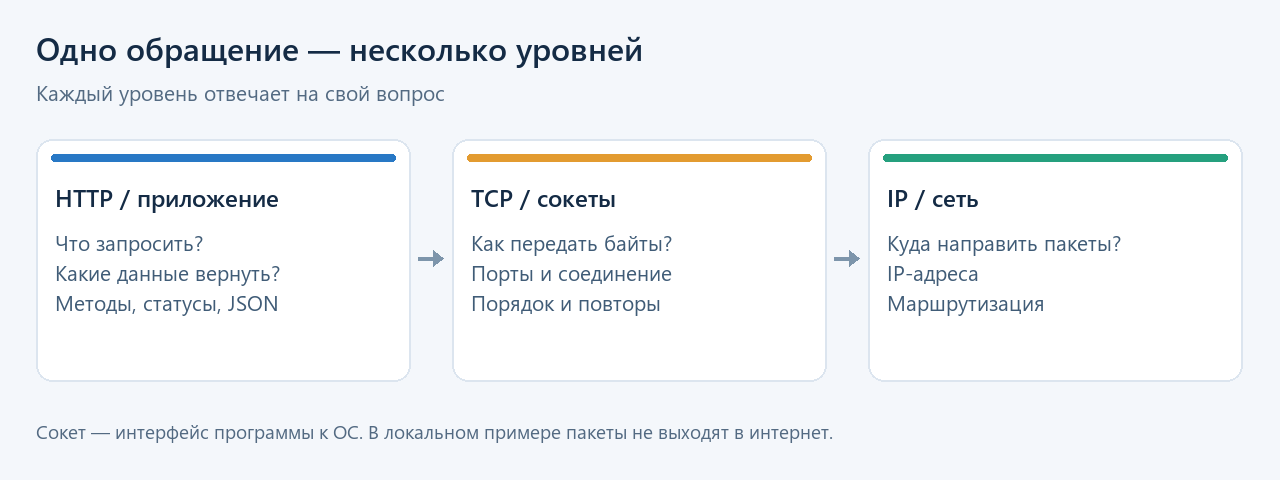

*Схема подготовлена для семинара.*

### 1.3. Что происходит при обращении к сервису

1. Программа выбирает адрес сервера. Если указан домен, DNS помогает найти IP-адрес.
2. Клиент соединяется с определённым портом сервера.
3. Программы обмениваются данными по правилам выбранного протокола.
4. Клиент разбирает ответ и использует результат.

Сегодня адрес уже известен: `127.0.0.1`. Это **loopback**, обращение к своему компьютеру.
Данные наших примеров не идут через интернет или Wi-Fi-роутер.

> Реплика для доклада: «Сначала нужно добраться до нужной программы.
> Потом — договориться с ней о смысле передаваемых байтов».

# 2. TCP/IP, порты и сокеты
### 2.1. IP-адрес: куда доставлять пакеты

IP обеспечивает адресацию и маршрутизацию. IP сам по себе не гарантирует доставку пакетов
или порядок их прибытия.

- **IPv4:** например, `192.168.1.10` — четыре числа от 0 до 255.
- **IPv6:** например, `2001:db8::10` — другая форма записи и большее адресное пространство.
- **Loopback:** `127.0.0.1` для IPv4 и `::1` для IPv6.

Практическая оговорка: у одного компьютера может быть несколько IP-адресов;
IP не является уникальным постоянным «паспортом компьютера».

В следующей ячейке только разбираем адреса; сетевых запросов нет.

In [1]:
import ipaddress
import socket
from concurrent.futures import ThreadPoolExecutor

for value in ["192.168.1.10", "127.0.0.1", "2001:db8::10", "::1"]:
    address = ipaddress.ip_address(value)
    print(f"{value:16} | IPv{address.version} | loopback: {address.is_loopback}")

192.168.1.10     | IPv4 | loopback: False
127.0.0.1        | IPv4 | loopback: True
2001:db8::10     | IPv6 | loopback: False
::1              | IPv6 | loopback: True


### 2.2. Порт: к какому сервису обратиться

На одном узле могут работать несколько сетевых сервисов. **Порт** помогает операционной системе
направить обмен к нужному сокету. Это число в заголовке TCP или UDP, а не физический разъём.

```text
                          сервер 127.0.0.1
                         ┌───────────────────┐
                         │ TCP :8000 → книги │
       клиент ─────────> │ TCP :9000 → echo  │
                         │ TCP :5432 → БД   │
                         └───────────────────┘
```

`127.0.0.1:9000` читается как «локальный узел, порт 9000».
В Python адрес IPv4-сервиса передают парой: `("127.0.0.1", 9000)`.

| Пример порта | Обычное назначение |
|---|---|
| 80 | HTTP |
| 443 | HTTPS |
| 22 | SSH |
| 8000 / 9000 | Часто выбираются для локальных учебных сервисов |

Это соглашения: само число порта не определяет формат данных.
У TCP и UDP отдельные пространства портов. Номера лежат в диапазоне `0–65535`.
В наших примерах `bind((HOST, 0))` просит ОС выбрать свободный порт;
подключаться будем уже к выданному ненулевому номеру.

**Вопрос аудитории:** достаточно ли знать IP, если на компьютере работают два разных сервиса?

### 2.3. TCP: соединение и поток байтов

TCP предоставляет **двунаправленный упорядоченный поток байтов**.
При потерях сегментов TCP выполняет повторную передачу; приложение получает данные в порядке отправки.
Если обмен невозможно продолжить, приложение может получить ошибку или дождаться таймаута.
Надёжность TCP не означает, что серверная программа успешно обработала запрос.

Перед передачей данных обычно происходит трёхэтапное установление соединения:

```text
Клиент                              Сервер
   | ----------- SYN --------------> |  хочу соединиться
   | <---------- SYN + ACK --------- |  согласен, подтверждаю
   | ----------- ACK --------------> |  подтверждаю
   | <======== данные в обе стороны ========> |
```

Это схема; ниже мы не перехватываем пакеты SYN/ACK.
Установлением TCP-соединения занимается ОС при вызове `connect()`.

| TCP обеспечивает | TCP сам по себе не обеспечивает |
|---|---|
| Порядок байтов и повторную передачу при потерях | Границы сообщений приложения |
| Проверку целостности передаваемых данных | Понимание JSON, HTTP или текста |
| Управление потоком и перегрузкой сети | Шифрование; для этого обычно нужен TLS |

UDP, для сравнения, передаёт датаграммы с сохранением их границ, но сам не гарантирует
доставку или порядок. В примерах ниже используем TCP.

### 2.4. Сеть передаёт байты, а не Python-строки

`str` хранит текст, а `bytes` — последовательность байтов.
Перед отправкой кодируем строку; после получения декодируем её в той же кодировке.
Число символов и число байтов могут различаться.

In [2]:
text = "Привет, TCP!"
payload = text.encode("utf-8")

print("Текст:", text)
print("Символов:", len(text))
print("Байтов UTF-8:", len(payload))
print("Содержимое bytes:", payload)
print("Обратно в текст:", payload.decode("utf-8"))

Текст: Привет, TCP!
Символов: 12
Байтов UTF-8: 18
Содержимое bytes: b'\xd0\x9f\xd1\x80\xd0\xb8\xd0\xb2\xd0\xb5\xd1\x82, TCP!'
Обратно в текст: Привет, TCP!


### 2.5. Сокет: основные операции

| Сервер | Клиент |
|---|---|
| `socket()` — создать сокет | `socket()` — создать сокет |
| `bind()` — назначить локальный адрес и порт | `connect()` — подключиться к адресу сервера |
| `listen()` — начать слушать соединения | |
| `accept()` — принять соединение, получить **новый** сокет | |
| `recv()` / `sendall()` — принять / отправить байты | `sendall()` / `recv()` — отправить / принять байты |
| `close()` — освободить ресурс | `close()` — освободить ресурс |

**Важно:** слушающий сокет принимает соединения, а сокет, возвращённый `accept()`,
используется для обмена с конкретным клиентом. Порт сервера при этом не меняется.

- `AF_INET` выбирает IPv4; `SOCK_STREAM` в наших примерах выбирает TCP.
- `recv(1024)` получает **до** 1024 байтов, а не обязательно 1024.
- `recv()` может ждать данные; `settimeout()` ограничивает время ожидания операции.
- `b""` от `recv()` означает конец входящего потока, а не «пока нет данных».
- `sendall()` отправляет все переданные байты либо сообщает об ошибке.
- `with socket.socket(...) as sock:` закрывает сокет при выходе из блока.

Подробности интерфейса: [документация Python: socket](https://docs.python.org/3/library/socket.html).

### 2.6. Наш первый протокол: одна строка — один запрос

Echo-сервер возвращает полученную строку без изменений.
Договоримся, что текст закодирован в UTF-8, а символ новой строки `\n` завершает сообщение.
В одном соединении обмениваемся одним запросом и одним ответом.

Ниже — небольшая функция чтения: она собирает байты, пока не встретит разделитель.
Размер сообщения ограничиваем, чтобы случайная ошибка не приводила к бесконечному накоплению данных.

Эта функция специально рассчитана на **одно сообщение на соединение**.
Для нескольких сообщений нужно сохранять байты после разделителя; такой пример есть в дополнительной части.

In [3]:
HOST = "127.0.0.1"
TIMEOUT = 5  # секунд на одну блокирующую операцию


def recv_line(sock, chunk_size=1024, max_bytes=4096):
    data = bytearray()
    while b"\n" not in data:
        chunk = sock.recv(chunk_size)
        if not chunk:
            raise EOFError("Поток закончился до разделителя сообщения")
        data.extend(chunk)
        if len(data) > max_bytes:
            raise ValueError("Сообщение слишком длинное для учебного протокола")
    return bytes(data).split(b"\n", 1)[0]

### 2.7. Живой пример: echo-сервер и клиент

**Перед запуском предскажите:** какой текст получит клиент и какие порты будут у обеих сторон?

Сервер и клиент находятся в одной ячейке, но работают одновременно:
сервер — в фоновом потоке, клиент — в основном.
`ThreadPoolExecutor` нужен здесь для организации демонстрации, а не для работы TCP.

Сначала разберите функцию сервера, затем клиентский блок.
`future.result()` дожидается окончания сервера и передаёт его исключение в основную ячейку, если оно возникло.

In [4]:
def echo_once(listener):
    connection, peer = listener.accept()  # отдельный сокет для клиента
    with connection:
        connection.settimeout(TIMEOUT)
        message = recv_line(connection)
        connection.sendall(message + b"\n")
    return peer, message


with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as listener:
    listener.bind((HOST, 0))  # ОС выбирает свободный порт
    listener.listen(1)
    listener.settimeout(TIMEOUT)
    server_address = listener.getsockname()
    print("Сервер слушает:", server_address)

    with ThreadPoolExecutor(max_workers=1) as pool:
        future = pool.submit(echo_once, listener)

        with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as client:
            client.settimeout(TIMEOUT)
            client.connect(server_address)
            client_address = client.getsockname()
            print("Локальный адрес клиента:", client_address)
            print("Адрес его собеседника:", client.getpeername())

            request = "Привет от Python!"
            client.sendall((request + "\n").encode("utf-8"))
            response = recv_line(client).decode("utf-8")
            print("Ответ:", response)

        peer, received = future.result(timeout=TIMEOUT)
        print("Сервер получил:", received.decode("utf-8"))
        print("Сервер видит клиента как:", peer)
        assert response == request
        assert peer == client_address

print("Обмен завершён; сокеты закрыты.")

Сервер слушает: ('127.0.0.1', 50118)
Локальный адрес клиента: ('127.0.0.1', 50119)
Адрес его собеседника: ('127.0.0.1', 50118)
Ответ: Привет от Python!
Сервер получил: Привет от Python!
Сервер видит клиента как: ('127.0.0.1', 50119)
Обмен завершён; сокеты закрыты.


### 2.8. Что видно в результате

- У клиента тоже есть порт: если его не задавать, ОС выбирает его автоматически.
- Сервер видит тот же адрес клиента, который показал `client.getsockname()`.
- TCP-соединение различается по двум концам:
  **IP клиента + порт клиента + IP сервера + порт сервера**.
- Поэтому несколько клиентов могут одновременно обращаться к одному порту сервера.
- Новые запуски могут показывать другие номера портов — это нормально.

**Мини-эксперимент:** измените `request` на `"Книга №1 📚"` и повторно выполните echo-ячейку.
Затем попробуйте `recv_line(client, chunk_size=3)` вместо `recv_line(client)`.
Итоговый текст должен остаться тем же.

Нельзя вставлять новую строку внутрь `request`: в нашем протоколе она завершает сообщение.

> Здесь можно закончить основной сетевой блок и перейти к HTTP.
> Следующие два эксперимента — дополнительно.

### Дополнительно A. Почему один sendall() — не одно сообщение для recv()

Отправим две строки **одним** вызовом `sendall()`, а читать будем маленькими кусками.
Размер чтения специально задаём равным трём байтам, чтобы эффект воспроизводился.

Это не демонстрация размеров сетевых пакетов: размеры результатов `recv()`
не позволяют определить границы TCP-сегментов или IP-пакетов.

In [5]:
def send_two_lines(listener):
    connection, _ = listener.accept()
    with connection:
        connection.settimeout(TIMEOUT)
        connection.sendall("Привет\nМир\n".encode("utf-8"))  # один вызов


with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as listener:
    listener.bind((HOST, 0))
    listener.listen(1)
    listener.settimeout(TIMEOUT)

    with ThreadPoolExecutor(max_workers=1) as pool:
        future = pool.submit(send_two_lines, listener)
        with socket.create_connection(listener.getsockname(), timeout=TIMEOUT) as client:
            chunks = []
            while True:
                chunk = client.recv(3)  # не больше трёх байтов за вызов
                if not chunk:
                    break  # сервер закрыл соединение; больше байтов не будет
                chunks.append(chunk)
                print("recv(3) →", repr(chunk))
        future.result(timeout=TIMEOUT)

raw = b"".join(chunks)
messages = [part.decode("utf-8") for part in raw.split(b"\n")[:-1]]
print("Собранный поток:", repr(raw))
print("Сообщения по нашему протоколу:", messages)
assert messages == ["Привет", "Мир"]

recv(3) → b'\xd0\x9f\xd1'
recv(3) → b'\x80\xd0\xb8'
recv(3) → b'\xd0\xb2\xd0'
recv(3) → b'\xb5\xd1\x82'
recv(3) → b'\n\xd0\x9c'
recv(3) → b'\xd0\xb8\xd1'
recv(3) → b'\x80\n'
Собранный поток: b'\xd0\x9f\xd1\x80\xd0\xb8\xd0\xb2\xd0\xb5\xd1\x82\n\xd0\x9c\xd0\xb8\xd1\x80\n'
Сообщения по нашему протоколу: ['Привет', 'Мир']


### Как правильно отделять сообщения

TCP знает порядок байтов, но не знает, где заканчивается «Привет» и начинается «Мир».
В предыдущем примере разделитель задаётся нашим протоколом.

Обычные варианты:

| Правило | Пример |
|---|---|
| Разделитель | Строка заканчивается `\n` |
| Длина в начале | Сначала число байтов сообщения, затем само сообщение |
| Фиксированная длина | Каждая запись занимает ровно 16 байтов |
| Конец входящего потока | Читаем до `recv() == b""` |

В эксперименте мы накопили весь короткий поток до закрытия и затем разделили его на строки.
В долгоживущем соединении нужен буфер: извлекаем завершённые сообщения,
а незавершённый остаток сохраняем до следующего чтения.

Байты одного UTF-8 символа тоже могут попасть в разные чтения.
Поэтому отдельный `chunk.decode("utf-8")` может завершиться ошибкой.
Мы декодируем уже собранные сообщения.

Подробнее: [Python Socket Programming HOWTO — Using a Socket](https://docs.python.org/3/howto/sockets.html#using-a-socket).

### Дополнительно B. Адрес есть, но сервер не слушает

IP-адрес не гарантирует, что на выбранном порту доступен сервис.
Зарезервируем локальный порт через `bind()`, но **не вызовем `listen()`**.
Попытка TCP-соединения завершится ошибкой: возможны `ConnectionRefusedError`
или `TimeoutError`. Конкретный результат зависит от ОС и настроек фильтрации трафика.

Удерживаем сокет открытым, чтобы порт не заняла другая программа.
Это управляемая локальная ошибка, а не сканирование чужих сервисов.

In [6]:
with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as not_listening:
    not_listening.bind((HOST, 0))  # порт занят нами, но соединения не принимаются
    address = not_listening.getsockname()
    print("Пробуем соединиться с:", address)

    try:
        with socket.create_connection(address, timeout=2):
            raise AssertionError("Неожиданно удалось подключиться")
    except ConnectionRefusedError:
        print("ConnectionRefusedError: на этом порту нет слушающего TCP-сервера.")
    except TimeoutError:
        print("TimeoutError: соединение не установилось за 2 секунды.")
        print("Конкретная ошибка зависит от ОС и настроек фильтрации трафика.")

Пробуем соединиться с: ('127.0.0.1', 50122)


TimeoutError: соединение не установилось за 2 секунды.
Конкретная ошибка зависит от ОС и настроек фильтрации трафика.


### Проверяем понимание

1. В чём разница между IP-адресом и портом?
2. Зачем нужен отдельный сокет, который вернул `accept()`?
3. Почему `recv(1024)` не означает «прочитать сообщение целиком»?
4. Как две программы определяют конец сообщения?
5. Почему текст нужно кодировать перед отправкой?

<details>
<summary>Ответы для ведущего</summary>

1. IP участвует в адресации узла; порт помогает найти нужный сетевой сервис на нём.
2. Слушающий сокет принимает соединения; новый сокет обслуживает обмен с конкретным клиентом.
3. Можно получить меньше байтов, часть сообщения или байты нескольких сообщений.
4. По правилам прикладного протокола: разделитель, длина, фиксированный размер или конец потока.
5. Сокет передаёт байты; кодировка определяет соответствие между текстом и байтами.

</details>

**Переход к следующей части:** мы написали свой протокол «строка до `\n`».
Чтобы работать с веб-сервисом, нужно использовать его протокол запросов и ответов — HTTP.

# 3. HTTP: методы, коды состояния и заголовки

**Основной маршрут — 12 минут:** запрос и ответ (3), GET и POST (3), методы и статусы (3),
заголовки и обработка ответа (3). Таблицы служат шпаргалкой;
дополнительные эксперименты можно пропустить при показе.

В echo-примере мы сами договорились о разделителе `\n`.
**HTTP — готовый прикладной протокол:** он задаёт структуру запроса и ответа,
смысл методов, кодов состояния и заголовков.
С HTTP можно получать HTML, JSON, изображения и другие данные.

Для читаемых примеров используем **HTTP/1.1**. В HTTP/2 и HTTP/3 представление сообщений
на транспортном уровне другое, но методы, статусы и назначение заголовков сохраняются.
HTTPS добавляет защиту обмена через TLS; локальный учебный сервер ниже использует HTTP.

Источник и иллюстрации: [MDN — обзор HTTP](https://developer.mozilla.org/en-US/docs/Web/HTTP/Guides/Overview).

### 3.1. Разбираем URL

```text
http://127.0.0.1:8000/books?q=Python#results
└─┬─┘  └───┬───┘ └┬─┘ └─┬─┘ └──┬───┘ └──┬──┘
 схема     хост    порт  путь   query    fragment
```

- **Схема:** `http` или `https`.
- **Хост и порт:** адрес сервиса; стандартные порты — 80 и 443 соответственно.
- **Путь:** какой ресурс нужен, например `/books`.
- **Query:** параметры после `?`; несколько параметров разделяют `&`.
- **Fragment:** часть после `#`; в HTTP-запрос к серверу она не отправляется.

В следующих ячейках ОС сама выберет свободный порт, поэтому фактический URL будет отличаться.

In [7]:
from urllib.parse import urlsplit, parse_qs

url = "http://127.0.0.1:8000/books?q=Python#results"
parts = urlsplit(url)
print("Схема:", parts.scheme)
print("Хост:", parts.hostname)
print("Порт:", parts.port)
print("Путь:", parts.path)
print("Параметры:", parse_qs(parts.query))
print("Фрагмент (не отправляется серверу):", parts.fragment)

Схема: http
Хост: 127.0.0.1
Порт: 8000
Путь: /books
Параметры: {'q': ['Python']}
Фрагмент (не отправляется серверу): results


### 3.2. Из чего состоят запрос и ответ

Запрос HTTP/1.1:

```http
GET /books?q=Python HTTP/1.1
Host: 127.0.0.1:8000
Accept: application/json

```

1. Первая строка: **метод + цель запроса + версия HTTP**.
2. Заголовки: дополнительные сведения. В HTTP/1.1 заголовок `Host` обязателен.
3. Пустая строка: граница между заголовками и телом.
4. Тело: может отсутствовать, как в нашем GET.

Ответ:

```http
HTTP/1.1 200 OK
Content-Type: application/json; charset=utf-8
Content-Length: 12

{"items":[]}
```

Первая строка содержит **версию + статус + краткое описание**.
Далее идут заголовки, пустая строка и тело, если оно предусмотрено.
Имена заголовков нечувствительны к регистру.

В байтах строки HTTP/1.1 разделяются `\r\n`, а конец блока заголовков обозначается `\r\n\r\n`.
`Content-Length` задаёт размер тела **в байтах**, а не число символов.
У HTTP есть и другие способы определить границы тела; здесь показываем вариант с длиной.

**Вопрос аудитории:** где в ответе заканчивается служебная информация и начинаются данные?

Схемы с подписями: [MDN — HTTP messages](https://developer.mozilla.org/en-US/docs/Web/HTTP/Guides/Messages).

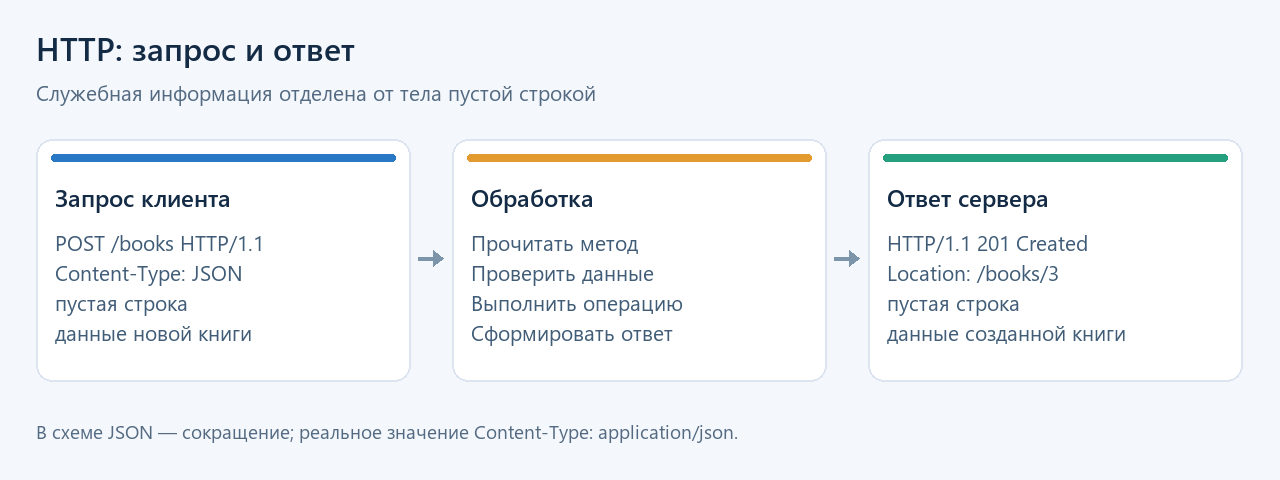

*Схема подготовлена для семинара; точный формат показан выше.*

### Подготовка учебного сервера

Выполните следующую ячейку один раз. Это инфраструктура демонстрации:
на докладе достаточно объяснить, что сервер хранит две книги и отвечает на HTTP-запросы.
Её код можно свернуть.

Каждый блок `with demo_http_server() as (base_url, http):` запускает свежий сервер,
а при выходе закрывает клиентскую сессию, сервер и его поток.
Так примеры можно повторять без накопления созданных книг и занятых портов.
Сами запросы и результаты будут в следующих коротких ячейках.

In [8]:
import json
import socket
import threading
from contextlib import contextmanager
from http.server import BaseHTTPRequestHandler, HTTPServer
from urllib.parse import urlsplit, parse_qs

import requests

HTTP_TIMEOUT = 5


class BookHTTPHandler(BaseHTTPRequestHandler):
    protocol_version = "HTTP/1.1"

    def log_message(self, format, *args):
        pass  # результаты запросов выводим сами, без служебного лога

    def setup(self):
        super().setup()
        self.connection.settimeout(HTTP_TIMEOUT)
        self.body_consumed = False

    def read_body(self):
        size = int(self.headers.get("Content-Length", "0"))
        if not 0 <= size <= 16384:
            raise ValueError("Недопустимая длина тела")
        self.body_consumed = True
        return self.rfile.read(size)

    def route(self):
        return urlsplit(self.path).path

    def reply(self, status, value=None, **headers):
        # Читаем также отвергнутое тело: закрытие с непрочитанными данными
        # может сбросить TCP-соединение раньше, чем клиент получит ответ.
        if not self.body_consumed:
            try:
                self.read_body()
            except ValueError:
                pass
        body = b"" if value is None else json.dumps(value, ensure_ascii=False).encode("utf-8")
        self.send_response(status)
        if value is not None:
            self.send_header("Content-Type", "application/json; charset=utf-8")
        if status != 204:
            self.send_header("Content-Length", str(len(body)))
        self.send_header("Connection", "close")
        self.send_header("X-Seminar", "HTTP-demo")
        for key, value in headers.items():
            self.send_header(key.replace("_", "-"), str(value))
        self.end_headers()
        if self.command != "HEAD" and status != 204:
            self.wfile.write(body)
        self.close_connection = True

    def item_id(self):
        tail = self.route().removeprefix("/books/")
        return int(tail) if self.route().startswith("/books/") and tail.isdigit() else None

    def read_json(self):
        if self.headers.get("Content-Type", "").split(";", 1)[0].strip().lower() != "application/json":
            self.reply(415, {"error": "Ожидается Content-Type: application/json"})
            return None
        try:
            value = json.loads(self.read_body().decode("utf-8"))
            if not isinstance(value, dict):
                raise ValueError("Ожидается JSON-объект")
        except (ValueError, UnicodeError):
            self.reply(400, {"error": "Некорректный JSON или длина тела"})
            return None
        return value

    def valid_book(self, value, partial=False):
        fields = {"title", "author"}
        return (bool(value) and set(value) <= fields
                and (partial or set(value) == fields)
                and all(isinstance(v, str) and v.strip() for v in value.values()))

    def do_GET(self):
        path = self.route()
        if path == "/books":
            query = parse_qs(urlsplit(self.path).query).get("q", [""])[0]
            items = [dict(b) for b in self.server.books.values()
                     if query.casefold() in b["title"].casefold()]
            self.reply(200, {"items": items, "query": query})
        elif self.item_id() in self.server.books:
            self.reply(200, self.server.books[self.item_id()])
        elif path == "/old-books":
            self.reply(302, Location="/books")
        elif path == "/unavailable":
            self.reply(503, {"error": "Учебная временная недоступность"}, Retry_After="2")
        else:
            self.reply(404, {"error": "Ресурс не найден"})

    def do_HEAD(self):
        self.do_GET()  # reply() отправит заголовки, но не тело

    def do_POST(self):
        if self.route() != "/books":
            self.reply(404, {"error": "Ресурс не найден"})
            return
        value = self.read_json()
        if value is None:
            return
        if not self.valid_book(value):
            self.reply(400, {"error": "Нужны непустые строки title и author"})
            return
        item_id = self.server.next_id
        self.server.next_id += 1
        book = {"id": item_id, **value}
        self.server.books[item_id] = book
        self.reply(201, book, Location=f"/books/{item_id}")

    def update_book(self, partial):
        if self.route() == "/books":
            self.reply(405, {"error": "Метод не разрешён для списка"},
                       Allow="GET, HEAD, POST, OPTIONS")
            return
        item_id = self.item_id()
        if item_id not in self.server.books:
            self.reply(404, {"error": "Ресурс не найден"})
            return
        value = self.read_json()
        if value is None:
            return
        if not self.valid_book(value, partial=partial):
            self.reply(400, {"error": "Некорректные поля книги"})
            return
        book = ({**self.server.books[item_id], **value} if partial
                else {"id": item_id, **value})
        self.server.books[item_id] = book
        self.reply(200, book)

    def do_PUT(self):
        self.update_book(partial=False)

    def do_PATCH(self):
        self.update_book(partial=True)

    def do_DELETE(self):
        if self.route() == "/books":
            self.reply(405, {"error": "Метод не разрешён для списка"},
                       Allow="GET, HEAD, POST, OPTIONS")
        elif self.item_id() in self.server.books:
            del self.server.books[self.item_id()]
            self.reply(204)
        else:
            self.reply(404, {"error": "Ресурс не найден"})

    def do_OPTIONS(self):
        if self.route() == "/books":
            self.reply(204, Allow="GET, HEAD, POST, OPTIONS")
        elif self.item_id() in self.server.books:
            self.reply(204, Allow="GET, HEAD, PUT, PATCH, DELETE, OPTIONS")
        else:
            self.reply(404, {"error": "Ресурс не найден"})


@contextmanager
def demo_http_server():
    with HTTPServer(("127.0.0.1", 0), BookHTTPHandler) as server:
        server.books = {
            1: {"id": 1, "title": "Python для начинающих", "author": "Анна"},
            2: {"id": 2, "title": "Компьютерные сети", "author": "Иван"},
        }
        server.next_id = 3
        worker = threading.Thread(target=server.serve_forever,
                                  kwargs={"poll_interval": 0.05}, daemon=True)
        with requests.Session() as http:
            http.trust_env = False  # локальные запросы без прокси из окружения
            worker.start()
            try:
                yield f"http://127.0.0.1:{server.server_port}", http
            finally:
                server.shutdown()
                worker.join(timeout=HTTP_TIMEOUT)
                if worker.is_alive():
                    raise RuntimeError("Поток учебного сервера не завершился")

print("HTTP-сервер подготовлен. Для каждого примера используйте demo_http_server().")

HTTP-сервер подготовлен. Для каждого примера используйте demo_http_server().


### 3.3. Настоящий HTTP через знакомый сокет

Отправим GET обычной строкой, закодированной в байты.
В этом конкретном примере просим сервер закрыть соединение после ответа
и читаем до конца входящего потока — не одним вызовом `recv()`.

**Смотрите на результат:** первая строка, заголовки, пустая строка, JSON.
HTTP не требует, чтобы каждое сообщение занимало отдельное TCP-соединение;
закрытие после ответа здесь упрощает демонстрацию.

In [9]:
with demo_http_server() as (base_url, http):
    address = urlsplit(base_url)
    request_text = (
        "GET /books?q=Python HTTP/1.1\r\n"
        f"Host: {address.netloc}\r\n"
        "Accept: application/json\r\n"
        "Connection: close\r\n\r\n"
    )
    print("=== ЗАПРОС ===")
    print(request_text)

    with socket.create_connection((address.hostname, address.port), timeout=HTTP_TIMEOUT) as client:
        client.sendall(request_text.encode("ascii"))
        chunks = []
        while True:
            chunk = client.recv(1024)
            if not chunk:
                break
            chunks.append(chunk)
    raw_response = b"".join(chunks)

print("=== ОТВЕТ ===")
print(raw_response.decode("utf-8"))
header_bytes, body_bytes = raw_response.split(b"\r\n\r\n", 1)
assert header_bytes.startswith(b"HTTP/1.1 200 ")
assert json.loads(body_bytes)["items"][0]["id"] == 1

=== ЗАПРОС ===
GET /books?q=Python HTTP/1.1
Host: 127.0.0.1:50125
Accept: application/json
Connection: close




=== ОТВЕТ ===
HTTP/1.1 200 OK
Server: BaseHTTP/0.6 Python/3.13.5
Date: Sat, 03 Oct 2026 17:17:16 GMT
Content-Type: application/json; charset=utf-8
Content-Length: 110
Connection: close
X-Seminar: HTTP-demo

{"items": [{"id": 1, "title": "Python для начинающих", "author": "Анна"}], "query": "Python"}


### 3.4. Тот же GET через requests

Библиотека составляет HTTP-сообщение и разбирает ответ за нас.
`params=` формирует и кодирует параметры URL; `headers=` задаёт заголовки запроса.

| Поле ответа | Что получаем |
|---|---|
| `status_code` | Числовой HTTP-статус |
| `headers` | Заголовки ответа |
| `content` | Тело в байтах |
| `text` | Тело как текст |
| `json()` | Результат разбора JSON: например, словарь |

`timeout=` ограничивает ожидание соединения и чтения, а не общее время всей операции.
`raise_for_status()` сообщает об HTTP-ошибках 4xx/5xx.
Сам вызов `json()` **не проверяет успешность запроса**.

In [10]:
with demo_http_server() as (base_url, http):
    response = http.get(
        f"{base_url}/books",
        params={"q": "Python"},
        headers={"Accept": "application/json", "User-Agent": "SeminarDemo/1.0"},
        timeout=HTTP_TIMEOUT,
    )
    response.raise_for_status()
    print("Фактический URL:", response.url)
    print("Метод:", response.request.method)
    print("Заголовки запроса:", dict(response.request.headers))
    print("Статус:", response.status_code)
    print("Заголовки ответа:", dict(response.headers))
    print("Тело как текст:", response.text)
    print("Тело как Python-объект:", response.json())
    assert response.status_code == 200
    assert len(response.json()["items"]) == 1

Фактический URL: http://127.0.0.1:50127/books?q=Python
Метод: GET
Заголовки запроса: {'User-Agent': 'SeminarDemo/1.0', 'Accept-Encoding': 'gzip, deflate, br, zstd', 'Accept': 'application/json', 'Connection': 'keep-alive'}
Статус: 200
Заголовки ответа: {'Server': 'BaseHTTP/0.6 Python/3.13.5', 'Date': 'Sat, 03 Oct 2026 17:17:16 GMT', 'Content-Type': 'application/json; charset=utf-8', 'Content-Length': '110', 'Connection': 'close', 'X-Seminar': 'HTTP-demo'}
Тело как текст: {"items": [{"id": 1, "title": "Python для начинающих", "author": "Анна"}], "query": "Python"}
Тело как Python-объект: {'items': [{'id': 1, 'title': 'Python для начинающих', 'author': 'Анна'}], 'query': 'Python'}


### 3.5. Заголовки: что отправляем и что ожидаем

| Заголовок | Смысл | Где покажем |
|---|---|---|
| `Host` | К какому хосту обращаемся | Запрос через сокет |
| `Accept` | Какие типы ответа клиент готов принять | GET и POST |
| `Content-Type` | Какой тип у **тела этого сообщения** | POST и ответ с JSON |
| `Content-Length` | Сколько байтов в теле | Сырой ответ и HEAD |
| `User-Agent` | Информация о клиенте | GET |
| `Location` | Адрес созданного ресурса или цель перенаправления | POST и redirect |
| `Allow` | Какие методы разрешены для ресурса | OPTIONS и 405 |
| `Retry-After` | Когда можно повторить запрос | Учебный ответ 503 |
| `Authorization` | Учётные данные для аутентификации | Следующий раздел про API |

**Accept и Content-Type — разные вещи.**
Можно отправить JSON (`Content-Type: application/json`) и попросить ответ другого типа через `Accept`.
Заголовок `Accept` сам не преобразует данные: сервер должен поддерживать согласование форматов.
Наш учебный каталог отвечает JSON и не реализует полное согласование.

Справка: [MDN — Accept](https://developer.mozilla.org/en-US/docs/Web/HTTP/Reference/Headers/Accept),
[MDN — Content-Type](https://developer.mozilla.org/en-US/docs/Web/HTTP/Reference/Headers/Content-Type).

### 3.6. POST: отправляем JSON и создаём книгу

Через `json=` передаём Python-словарь: библиотека сериализует его
и добавляет `Content-Type: application/json`.
Сервер отвечает **201 Created** и сообщает адрес новой книги в `Location`.
После создания сделаем GET по этому адресу.

На примере видно различие: query-параметры находятся в URL, данные новой книги — в теле запроса.

In [11]:
with demo_http_server() as (base_url, http):
    response = http.post(
        f"{base_url}/books",
        json={"title": "HTTP на практике", "author": "Мария"},
        headers={"Accept": "application/json"},
        timeout=HTTP_TIMEOUT,
    )
    response.raise_for_status()
    print("POST Content-Type:", response.request.headers["Content-Type"])
    print("POST body:", response.request.body.decode("utf-8"))
    print("Статус:", response.status_code)
    print("Созданная книга:", response.json())
    print("Location:", response.headers["Location"])

    created = http.get(base_url + response.headers["Location"], timeout=HTTP_TIMEOUT)
    created.raise_for_status()
    print("GET созданной книги:", created.json())
    assert response.status_code == 201
    assert created.json() == response.json()

POST Content-Type: application/json
POST body: {"title": "HTTP \u043d\u0430 \u043f\u0440\u0430\u043a\u0442\u0438\u043a\u0435", "author": "\u041c\u0430\u0440\u0438\u044f"}
Статус: 201
Созданная книга: {'id': 3, 'title': 'HTTP на практике', 'author': 'Мария'}
Location: /books/3
GET созданной книги: {'id': 3, 'title': 'HTTP на практике', 'author': 'Мария'}


### 3.7. Методы: действие и адрес ресурса

| Метод | Назначение | Пример в каталоге |
|---|---|---|
| GET | Получить представление ресурса | `GET /books/1` |
| POST | Передать данные для обработки; часто создать ресурс | `POST /books` |
| PUT | Создать или полностью заменить состояние по известному адресу | `PUT /books/1` |
| PATCH | Частично изменить ресурс | `PATCH /books/1` |
| DELETE | Удалить связь ресурса с его адресом | `DELETE /books/1` |
| HEAD | Как GET, но ответ без тела | `HEAD /books` |
| OPTIONS | Узнать возможности обращения к ресурсу | `OPTIONS /books` |

Конкретные адреса и поддерживаемые операции определяет сервер.
Наш сервер поддерживает PUT только для существующих книг.
В PATCH принимаем обычный объект с полями, которые надо изменить: это соглашение именно этого API.

**Безопасность метода** в HTTP означает, что клиент не запрашивает изменение состояния:
GET и HEAD предназначены для чтения. Это не характеристика шифрования.
**Идемпотентность** означает одинаковый предполагаемый эффект при повторении одной операции:
PUT и DELETE идемпотентны, POST и PATCH — не обязательно.
При повторении статус и тело ответа могут различаться.

**Вопрос аудитории:** чем замена всей книги отличается от изменения только её названия?

Справка: [MDN — HTTP methods](https://developer.mozilla.org/en-US/docs/Web/HTTP/Reference/Methods).

In [12]:
with demo_http_server() as (base_url, http):
    url = f"{base_url}/books/1"
    replacement = {"title": "Основы HTTP", "author": "Ольга"}

    put = http.put(url, json=replacement, timeout=HTTP_TIMEOUT)
    put.raise_for_status()
    print("PUT — полная замена:", put.status_code, put.json())

    patch = http.patch(url, json={"title": "Основы HTTP: новое издание"}, timeout=HTTP_TIMEOUT)
    patch.raise_for_status()
    print("PATCH — изменили только title:", patch.status_code, patch.json())
    assert patch.json()["author"] == "Ольга"

    deleted = http.delete(url, timeout=HTTP_TIMEOUT)
    print("DELETE:", deleted.status_code, "тело:", repr(deleted.content))
    assert deleted.status_code == 204 and deleted.content == b""

    missing = http.get(url, timeout=HTTP_TIMEOUT)
    print("GET после удаления:", missing.status_code, missing.json())
    assert missing.status_code == 404

PUT — полная замена: 200 {'id': 1, 'title': 'Основы HTTP', 'author': 'Ольга'}
PATCH — изменили только title: 200 {'id': 1, 'title': 'Основы HTTP: новое издание', 'author': 'Ольга'}
DELETE: 204 тело: b''
GET после удаления: 404 {'error': 'Ресурс не найден'}


### 3.8. Коды состояния: результат запроса

| Группа | Смысл | Примеры |
|---|---|---|
| 1xx | Промежуточная информация | 100 Continue |
| 2xx | Успешная обработка | 200 OK, 201 Created, 204 No Content |
| 3xx | Перенаправление или специальные условия получения | 302 Found, 304 Not Modified |
| 4xx | Запрос не может быть выполнен в переданном виде | 400, 401, 403, 404, 405, 415, 429 |
| 5xx | Проблема при обработке на стороне сервера | 500 Internal Server Error, 503 Service Unavailable |

Полезные различия:

- **400:** некорректный запрос, например сломанный JSON.
- **401:** отсутствуют действительные данные аутентификации; **403:** доступ запрещён.
- **404:** ресурс не найден; **405:** ресурс есть, но этот метод для него не разрешён.
- **415:** сервер не поддерживает переданный тип тела.
- **429:** слишком много запросов; **503:** сервис сейчас недоступен.
- **204:** операция успешна, тела ответа нет — `json()` вызывать не надо.

401/403 и 429 разберём в следующих разделах; ниже проверим 400, 404, 405, 415 и 503.
503 в нашем примере задан специально, это не случайная поломка сервера.

Справка: [MDN — HTTP status codes](https://developer.mozilla.org/en-US/docs/Web/HTTP/Reference/Status).

In [13]:
with demo_http_server() as (base_url, http):
    responses = [
        ("Сломанный JSON", http.post(
            f"{base_url}/books", data="{broken json",
            headers={"Content-Type": "application/json"}, timeout=HTTP_TIMEOUT)),
        ("Ресурса нет", http.get(f"{base_url}/missing", timeout=HTTP_TIMEOUT)),
        ("PUT для списка не разрешён", http.put(
            f"{base_url}/books", json={"title": "Пример"}, timeout=HTTP_TIMEOUT)),
        ("Форма вместо JSON", http.post(
            f"{base_url}/books", data={"title": "Пример", "author": "Анна"}, timeout=HTTP_TIMEOUT)),
        ("Временная недоступность", http.get(f"{base_url}/unavailable", timeout=HTTP_TIMEOUT)),
    ]
    for label, response in responses:
        print(f"{response.status_code} | {label}: {response.json()['error']}")
        if "Allow" in response.headers:
            print("      Allow:", response.headers["Allow"])
        if "Retry-After" in response.headers:
            print("      Retry-After:", response.headers["Retry-After"])
    assert [r.status_code for _, r in responses] == [400, 404, 405, 415, 503]

    # Валидный JSON с описанием ошибки не делает запрос успешным.
    failed = responses[1][1]
    try:
        failed.raise_for_status()
    except requests.HTTPError as error:
        print("raise_for_status() →", type(error).__name__, "для статуса", failed.status_code)

400 | Сломанный JSON: Некорректный JSON или длина тела
404 | Ресурса нет: Ресурс не найден
405 | PUT для списка не разрешён: Метод не разрешён для списка
      Allow: GET, HEAD, POST, OPTIONS
415 | Форма вместо JSON: Ожидается Content-Type: application/json
503 | Временная недоступность: Учебная временная недоступность
      Retry-After: 2
raise_for_status() → HTTPError для статуса 404


### 3.9. Как читать результат запроса

1. Обработать сетевую ошибку, если ответа вообще не удалось получить.
2. Проверить HTTP-статус: тело с JSON может содержать описание ошибки.
3. Учесть, предусмотрено ли тело: у HEAD и 204 его нет.
4. Проверить тип данных и разобрать тело нужным способом.

`ConnectionError` и `Timeout` — ошибки обмена, а 404/503 — полученные HTTP-ответы.
В `requests` ответы 4xx/5xx сами по себе не вызывают исключение;
его создаёт вызов `raise_for_status()`.
HTML-ответ нельзя автоматически считать JSON только потому, что мы ожидаем данные API.

Практическая справка: [Requests — Quickstart](https://requests.readthedocs.io/en/latest/user/quickstart/).

### Дополнительно C. HEAD и OPTIONS

HEAD позволяет получить заголовки без тела ответа.
Обратите внимание: его `Content-Length` описывает тело соответствующего GET,
а не длину пустого тела HEAD.
OPTIONS в нашем сервисе возвращает допустимые методы в `Allow`.

In [14]:
with demo_http_server() as (base_url, http):
    url = f"{base_url}/books"
    get = http.get(url, timeout=HTTP_TIMEOUT)
    head = http.head(url, timeout=HTTP_TIMEOUT)
    options = http.options(url, timeout=HTTP_TIMEOUT)

    print("GET:", get.status_code, "получено байтов:", len(get.content))
    print("HEAD:", head.status_code, "получено байтов:", len(head.content))
    print("HEAD Content-Length:", head.headers["Content-Length"])
    print("OPTIONS:", options.status_code, "Allow:", options.headers["Allow"])
    assert head.content == b""
    assert int(head.headers["Content-Length"]) == len(get.content)
    assert options.status_code == 204 and options.content == b""

GET: 200 получено байтов: 183
HEAD: 200 получено байтов: 0
HEAD Content-Length: 183
OPTIONS: 204 Allow: GET, HEAD, POST, OPTIONS


### Дополнительно D. Перенаправление и Location

`GET /old-books` отвечает 302 и указывает новый адрес `/books`.
В `requests` GET обычно следует перенаправлению автоматически;
`allow_redirects=False` позволяет увидеть исходный ответ.
Для POST и других изменяющих запросов правила перенаправления различаются по статусам;
в этой демонстрации используем только GET.

In [15]:
with demo_http_server() as (base_url, http):
    url = f"{base_url}/old-books"
    first = http.get(url, allow_redirects=False, timeout=HTTP_TIMEOUT)
    followed = http.get(url, timeout=HTTP_TIMEOUT)

    print("Без перехода:", first.status_code, "Location:", first.headers["Location"])
    print("После перехода:", followed.status_code, "URL:", followed.url)
    print("История:", [r.status_code for r in followed.history])
    assert first.status_code == 302
    assert followed.status_code == 200
    assert [r.status_code for r in followed.history] == [302]

Без перехода: 302 Location: /books
После перехода: 200 URL: http://127.0.0.1:50147/books
История: [302]


### Проверяем понимание HTTP

1. Как отличить тело сообщения от заголовков в HTTP/1.1?
2. Чем `Accept` отличается от `Content-Type`?
3. Чем PUT отличается от PATCH?
4. Почему успешный вызов `response.json()` не доказывает, что запрос успешен?
5. Чем 404 отличается от ошибки TCP-соединения?
6. Можно ли вызвать `json()` у ответа 204?

<details>
<summary>Ответы для ведущего</summary>

1. Блок заголовков завершается пустой строкой, в байтах — `\r\n\r\n`.
2. Accept сообщает о допустимом формате ответа, Content-Type — о формате тела данного сообщения.
3. PUT задаёт замену состояния ресурса целиком; PATCH описывает частичное изменение.
4. Сервер может вернуть корректный JSON с описанием ошибки и статусом 4xx/5xx.
5. 404 — ответ HTTP-сервера; при ошибке TCP-соединения HTTP-ответа может вообще не быть.
6. Тела у 204 нет, поэтому разбор JSON закончится ошибкой.

</details>

**Переход к REST:** мы умеем читать HTTP-сообщения и выполнять операции с книгами.
Следующий вопрос — как организовать понятный API вокруг ресурсов и работать с ним как клиент.

# 4. REST API, аутентификация и API-ключи

**10 минут:** ресурсы и контракт API (3), ключи и токены (4), клиентская функция (3).
Продолжаем сценарий каталога книг, но теперь обращаемся к защищённому API.

### 4.1. Что означает REST

REST — архитектурный стиль. В HTTP API его удобно объяснять через ресурсы и их представления:
`/api/v1/books` — коллекция, `/api/v1/books/1` — конкретная книга, JSON — её представление.
Метод сообщает действие, URL — над каким ресурсом его выполнить.

Основные ограничения REST: клиент и сервер, stateless-обмен, единообразный интерфейс,
явные правила кэширования, возможность промежуточных слоёв; исполнение загружаемого кода необязательно.
Единообразный интерфейс включает идентификацию ресурсов, работу через представления,
самоописываемые сообщения и ссылки, направляющие дальнейшие действия клиента.

**Stateless не запрещает хранить книги в базе.** Запрос не должен зависеть от скрытого контекста
прошлых обращений конкретного клиента. Сервис возвращает `_links` и явно запрещает
кэширование защищённых ответов через `Cache-Control: no-store`.
Это учебный API с элементами REST, а не полная реализация всех архитектурных ограничений.

Первоисточник и схемы: [Roy Fielding — REST](https://ics.uci.edu/~fielding/pubs/dissertation/rest_arch_style.htm).

### 4.2. Сначала читаем контракт сервиса

Выясняем адрес, методы, параметры, формат ответа, способ аутентификации и ограничения.

| Обращение в нашем сервисе | Что возвращает |
|---|---|
| `GET /api/v1/books?page=1&per_page=3` | `items`, `next`, `total` |
| `GET /api/v1/books/1` | Книгу и ссылки `_links` |
| `GET /api/v1/admin` | Сводку; нужен ключ администратора |
| `GET /api/v1/profile` | Профиль; нужен демонстрационный Bearer-токен |

Для книг используется заголовок `X-API-Key`: `demo-reader-key` — чтение,
`demo-admin-key` — чтение и административная сводка.
Для профиля: `Authorization: Bearer demo-access-token`.
Все эти строки публичные, вымышленные и годятся только для локального примера.

### Подготовка сервиса для оставшихся разделов

Следующая свёрнутая ячейка добавляет защищённые ресурсы, страницы данных,
управляемые ошибки, лимит запросов и две HTML-страницы.
Выполните её после подготовки HTTP-сервера из раздела 3.

In [16]:
import html
import math
import time
from urllib.parse import urlencode


class SeminarHandler(BookHTTPHandler):
    def authorize(self, admin=False, bearer=False):
        if bearer:
            if self.headers.get("Authorization") != "Bearer demo-access-token":
                self.reply(401, {"error": "Нужен действительный Bearer-токен"},
                           WWW_Authenticate='Bearer realm="seminar"')
                return False
        else:
            role = self.server.api_keys.get(self.headers.get("X-API-Key"))
            if role is None:
                self.reply(401, {"error": "API-ключ отсутствует или неверен"},
                           WWW_Authenticate='ApiKey realm="seminar"')
                return False
            if admin and role != "admin":
                self.reply(403, {"error": "Нужны права администратора"})
                return False
        return True

    def reply_text(self, text, content_type="text/html; charset=utf-8"):
        if not self.body_consumed:
            self.read_body()
        body = text.encode("utf-8")
        self.send_response(200)
        self.send_header("Content-Type", content_type)
        self.send_header("Content-Length", str(len(body)))
        self.send_header("Connection", "close")
        self.end_headers()
        if self.command != "HEAD":
            self.wfile.write(body)
        self.close_connection = True

    def allowed_by_rate_limit(self):
        now = time.monotonic()
        if self.server.window_start is None or now - self.server.window_start >= 1:
            self.server.window_start = now
            self.server.window_count = 0
        if self.server.window_count >= 2:
            wait = max(1, math.ceil(1 - (now - self.server.window_start)))
            self.reply(429, {"error": "Не более двух запросов за секундное окно"},
                       Retry_After=wait, X_RateLimit_Limit=2, X_RateLimit_Remaining=0)
            return False
        self.server.window_count += 1
        return True

    def temporary_failure(self):
        self.server.flaky_count += 1
        if self.server.flaky_count <= 2:
            self.reply(503, {"error": "Учебный сбой", "attempt": self.server.flaky_count})
            return True
        return False

    def api_books(self, query):
        try:
            page = int(query.get("page", ["1"])[0])
            per_page = int(query.get("per_page", ["3"])[0])
            if page < 1 or not 1 <= per_page <= 20:
                raise ValueError
        except ValueError:
            self.reply(400, {"error": "page >= 1, per_page от 1 до 20"})
            return
        if query.get("resilient") == ["1"]:
            if not self.allowed_by_rate_limit() or self.temporary_failure():
                return
        ordered = [self.server.books[k] for k in sorted(self.server.books)]
        start = (page - 1) * per_page
        next_query = {"page": page + 1, "per_page": per_page}
        if query.get("resilient") == ["1"]:
            next_query["resilient"] = 1
        next_url = "/api/v1/books?" + urlencode(next_query) if start + per_page < len(ordered) else None
        self.reply(200, {"items": ordered[start:start+per_page], "page": page,
                         "total": len(ordered), "next": next_url}, Cache_Control="no-store")

    def do_GET(self):
        path = self.route()
        query = parse_qs(urlsplit(self.path).query)
        if path == "/api/v1/profile":
            if self.authorize(bearer=True):
                self.reply(200, {"user": "seminar-reader", "scope": ["books:read"]}, Cache_Control="no-store")
        elif path.startswith("/api/v1/"):
            if not self.authorize(admin=path == "/api/v1/admin"):
                return
            if path == "/api/v1/books":
                self.api_books(query)
            elif path == "/api/v1/admin":
                self.reply(200, {"book_count": len(self.server.books)}, Cache_Control="no-store")
            elif path.startswith("/api/v1/books/") and path.removeprefix("/api/v1/books/").isdigit():
                item_id = int(path.removeprefix("/api/v1/books/"))
                if item_id in self.server.books:
                    self.reply(200, {**self.server.books[item_id], "_links": {
                        "self": path, "collection": "/api/v1/books"}}, Cache_Control="no-store")
                else:
                    self.reply(404, {"error": "Книга не найдена"})
            else:
                self.reply(404, {"error": "Ресурс API не найден"})
        elif path == "/unstable":
            if not self.temporary_failure():
                self.reply(200, {"message": "Сервис восстановился", "attempt": self.server.flaky_count})
        elif path == "/limited":
            if self.allowed_by_rate_limit():
                self.reply(200, {"message": "Запрос принят"}, X_RateLimit_Limit=2,
                           X_RateLimit_Remaining=2-self.server.window_count)
        elif path == "/robots.txt":
            self.reply_text("User-agent: *\nDisallow: /private/\nAllow: /catalog\nCrawl-delay: 1\n", "text/plain; charset=utf-8")
        elif path == "/catalog":
            self.reply_text(catalog_html(self.server.books.values(), rendered=True))
        elif path == "/catalog-js":
            self.reply_text(catalog_html([], rendered=False))
        elif path == "/public/books-data":
            self.reply(200, {"items": [{**book, "price": f"{499 + book['id'] * 100}.00"}
                                      for book in self.server.books.values()]})
        else:
            super().do_GET()


def catalog_html(books, rendered):
    cards = "".join(
        f'<article class="book" data-id="{b["id"]}"><a class="title" href="/books/{b["id"]}">'
        f'{html.escape(b["title"])}</a><p class="author">{html.escape(b["author"])}</p>'
        f'<span class="price" data-price="{499+b["id"]*100}.00">{499+b["id"]*100},00 ₽</span></article>'
        for b in books)
    script = "" if rendered else r'''
<script>
setTimeout(async () => {
  try {
    const response = await fetch('/public/books-data');
    if (!response.ok) throw new Error('HTTP ' + response.status);
    const data = await response.json();
    const list = document.querySelector('#books');
    for (const book of data.items) {
      const card = document.createElement('article'); card.className = 'book'; card.dataset.id = book.id;
      const link = document.createElement('a'); link.className = 'title';
      link.href = '/books/' + book.id; link.textContent = book.title;
      const author = document.createElement('p'); author.className = 'author'; author.textContent = book.author;
      const price = document.createElement('span'); price.className = 'price';
      price.dataset.price = book.price; price.textContent = book.price.replace('.', ',') + ' ₽';
      card.append(link, author, price); list.append(card);
    }
    list.dataset.ready = 'true'; document.querySelector('#status').textContent = 'Данные загружены JavaScript';
  } catch (error) { document.querySelector('#status').textContent = error.message; }
}, 1200);
</script>
'''
    return ("<!doctype html><html lang='ru'><head><meta charset='utf-8'><title>Учебный каталог книг</title>"
            "<style>body{font:18px 'Segoe UI',sans-serif;background:#f4f7fb;color:#18324f;margin:40px}"
            "h1{margin-bottom:8px}.intro{color:#57718c}#books{display:grid;grid-template-columns:repeat(3,1fr);gap:18px}"
            ".book{background:white;padding:22px;border-radius:14px;border:1px solid #dce6ef}"
            ".title{font-size:21px;font-weight:600;color:#216cb0;text-decoration:none}"
            ".author{color:#65798e}.price{font-weight:600;color:#188369}</style></head><body>"
            "<h1>Каталог книг</h1><p class='intro'>Один источник данных: API, HTML и JavaScript</p>"
            f"<p id='status'>{'HTML уже содержит данные' if rendered else 'Загружаем данные…'}</p>"
            f"<section id='books' data-ready='{'true' if rendered else 'false'}'>{cards}</section>"
            + script + "</body></html>")


@contextmanager
def demo_service():
    with HTTPServer(("127.0.0.1", 0), SeminarHandler) as server:
        titles = ["Python для начинающих", "Компьютерные сети", "HTTP на практике", "REST API",
                  "Анализ данных", "Веб-скрейпинг", "Надёжные приложения", "Асинхронный Python"]
        server.books = {i: {"id": i, "title": title, "author": f"Автор {i}"}
                        for i, title in enumerate(titles, 1)}
        server.next_id = 9
        server.api_keys = {"demo-reader-key": "reader", "demo-admin-key": "admin"}
        server.flaky_count = 0
        server.window_start = None
        server.window_count = 0
        worker = threading.Thread(target=server.serve_forever,
                                  kwargs={"poll_interval": 0.05}, daemon=True)
        with requests.Session() as http:
            http.trust_env = False
            worker.start()
            try:
                yield f"http://127.0.0.1:{server.server_port}", http
            finally:
                server.shutdown()
                worker.join(timeout=HTTP_TIMEOUT)
                if worker.is_alive():
                    raise RuntimeError("Поток сервера не завершился")

print("Подготовлен сервис: REST, ключи, paging, retry, rate limiting, HTML и JS.")

Подготовлен сервис: REST, ключи, paging, retry, rate limiting, HTML и JS.


### 4.3. Аутентификация: кто обращается? Авторизация: что разрешено?

**API-ключ** часто идентифицирует приложение или проект и связан с правами и квотой.
**Bearer-токен** позволяет выполнить запрос тому, кто им обладает; он может иметь срок действия и ограниченные права.
OAuth описывает получение и использование доступа; JWT — один из возможных форматов токена.
Не каждый Bearer-токен является JWT.

Реальные ключи хранят вне ноутбука, например читают `os.environ["BOOKS_API_KEY"]`.
Их не включают в URL, опубликованные выводы или скриншоты; для реальных сервисов используют HTTPS.
Здесь секретов нет, поэтому демонстрационный ключ оставляем в учебной ячейке.

Стандарт Bearer: [RFC 6750](https://www.rfc-editor.org/rfc/rfc6750.html).

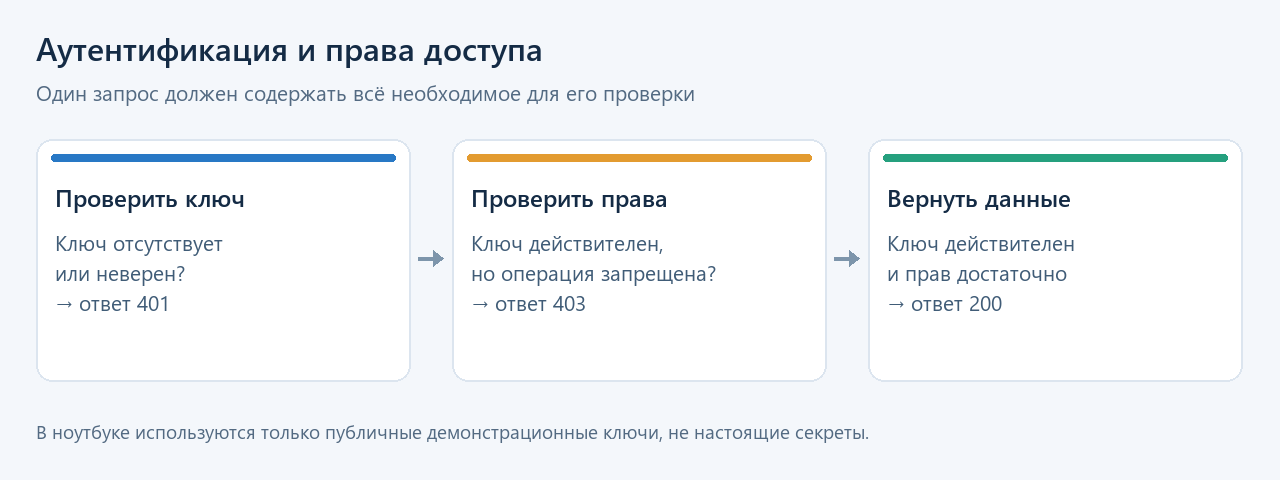

*Сначала проверяем учётные данные, затем права на операцию.*

In [17]:
with demo_service() as (base_url, http):
    cases = [
        ("Без ключа", "/api/v1/books", {}),
        ("Неверный ключ", "/api/v1/books", {"X-API-Key": "wrong-demo-key"}),
        ("Ключ читателя", "/api/v1/books", {"X-API-Key": "demo-reader-key"}),
        ("Читателю нельзя в admin", "/api/v1/admin", {"X-API-Key": "demo-reader-key"}),
        ("Ключ администратора", "/api/v1/admin", {"X-API-Key": "demo-admin-key"}),
    ]
    statuses = []
    for label, route, headers in cases:
        response = http.get(base_url + route, headers=headers, timeout=HTTP_TIMEOUT)
        statuses.append(response.status_code)
        print(label, "→", response.status_code)
    assert statuses == [401, 401, 200, 403, 200]

    profile = http.get(f"{base_url}/api/v1/profile",
                       headers={"Authorization": "Bearer demo-access-token"}, timeout=HTTP_TIMEOUT)
    profile.raise_for_status()
    print("Профиль через Bearer:", profile.json())

Без ключа → 401
Неверный ключ → 401
Ключ читателя → 200
Читателю нельзя в admin → 403


Ключ администратора → 200
Профиль через Bearer: {'user': 'seminar-reader', 'scope': ['books:read']}


### 4.4. Использование API: получаем представление и следуем ссылке

`requests.Session` задаёт общие заголовки для нескольких запросов.
Вспомогательная функция проверяет статус, тип ответа и разбирает JSON.
Клиент читает `_links.collection`, а не придумывает адрес следующего ресурса.

**Вопрос:** stateless означает, что сервер не хранит книги, или что каждый запрос самодостаточен?

In [18]:
def get_json(http, url, **kwargs):
    response = http.get(url, timeout=HTTP_TIMEOUT, **kwargs)
    response.raise_for_status()
    media_type = response.headers.get("Content-Type", "").split(";", 1)[0].strip().lower()
    if media_type != "application/json":
        raise ValueError(f"Ожидался JSON, получен {media_type!r}")
    return response.json()


from urllib.parse import urljoin

with demo_service() as (base_url, http):
    http.headers.update({"X-API-Key": "demo-reader-key", "Accept": "application/json"})
    book = get_json(http, f"{base_url}/api/v1/books/1")
    print("Ресурс:", {key: value for key, value in book.items() if key != "_links"})
    print("Ссылки:", book["_links"])
    collection = get_json(http, urljoin(base_url, book["_links"]["collection"]))
    print("Всего книг:", collection["total"], "в первом ответе:", len(collection["items"]))

Ресурс: {'id': 1, 'title': 'Python для начинающих', 'author': 'Автор 1'}
Ссылки: {'self': '/api/v1/books/1', 'collection': '/api/v1/books'}
Всего книг: 8 в первом ответе: 3


# 5. Много данных и временные ошибки

**13 минут:** paging (4), retry (5), rate limiting (4).
Наша задача — получить весь каталог, сохранив управляемое число запросов и попыток.

### 5.1. Paging: один ответ — только часть данных

| Вариант | Параметры | Особенности |
|---|---|---|
| Номер страницы | `page=2&per_page=3` | Удобно показывать страницы пользователю |
| Смещение | `offset=3&limit=3` | Пропускаем первые три записи |
| Курсор | `cursor=...&limit=3` | Сервер задаёт позицию следующей порции |

Восемь книг и размер страницы три — нужны три ответа.
**Не останавливаемся после первого успешного GET.** Следуем `next` до `null`.
У разных API следующая ссылка может находиться в теле или в HTTP-заголовке `Link`.

Порядок должен быть стабильным. При изменении набора page/offset могут давать пропуски или дубликаты;
курсор часто удобнее для больших изменяющихся наборов, но сам по себе не гарантирует снимок данных.

Реальный контракт: [GitHub — pagination](https://docs.github.com/en/rest/using-the-rest-api/using-pagination-in-the-rest-api).

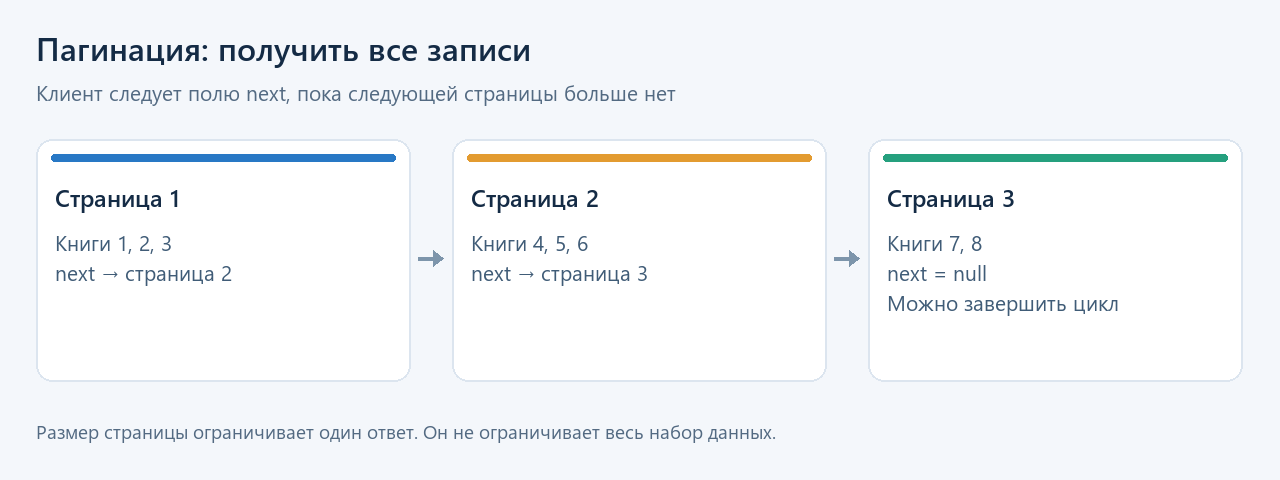

*В примере порядок фиксирован по id.*

In [19]:
def collect_books(http, first_url, fetch=get_json, max_pages=100):
    url = first_url
    origin = urlsplit(first_url)
    seen = set()
    result = []
    for page_number in range(1, max_pages + 1):
        if url in seen:
            raise RuntimeError("API вернул циклическую ссылку next")
        seen.add(url)
        target = urlsplit(url)
        if (target.scheme, target.netloc) != (origin.scheme, origin.netloc):
            raise ValueError("Следующая страница ведёт на другой источник")
        data = fetch(http, url)
        print(f"Страница {page_number}: {len(data['items'])} записей")
        result.extend(data["items"])
        if data["next"] is None:
            return result
        url = urljoin(url, data["next"])
    raise RuntimeError("Превышен предел числа страниц")


with demo_service() as (base_url, http):
    http.headers["X-API-Key"] = "demo-reader-key"
    books = collect_books(http, f"{base_url}/api/v1/books?page=1&per_page=3")
    print("Собрано:", len(books), "книг; id:", [b["id"] for b in books])
    assert [b["id"] for b in books] == list(range(1, 9))

Страница 1: 3 записей
Страница 2: 3 записей
Страница 3: 2 записей
Собрано: 8 книг; id: [1, 2, 3, 4, 5, 6, 7, 8]


### 5.2. Retry: какие запросы имеет смысл повторять

| Ситуация | Действие |
|---|---|
| Временная ошибка соединения или таймаут при GET | Ограниченный повтор, если это допускает контракт |
| 429, 502, 503, 504 | Кандидаты для повтора с ожиданием |
| 400, 401, 403, 404 | Исправить запрос, доступ или адрес; повтор без изменений обычно не поможет |
| Ошибка TLS-сертификата | Исправить причину, а не повторять автоматически |
| POST с потерянным ответом | Выяснить результат операции: повтор может создать дубликат |

**Backoff:** паузы растут, например 0,2 → 0,4 → 0,8 секунды.
**Jitter:** случайная добавка, чтобы клиенты не повторяли запросы одновременно.
`Retry-After` может содержать секунды или HTTP-дату; ждём не меньше указанного срока.

Ниже повторы **только GET**, максимум четыре попытки, с ограничением суммарного времени пауз.
Таймаут отдельного запроса обязателен; бюджет пауз не является общим дедлайном операции.
Для POST безопасный повтор возможен с ключом идемпотентности, если сервис поддерживает такую гарантию.

Справка: [Microsoft — transient faults](https://learn.microsoft.com/en-us/azure/architecture/best-practices/transient-faults),
[MDN — Retry-After](https://developer.mozilla.org/en-US/docs/Web/HTTP/Reference/Headers/Retry-After).

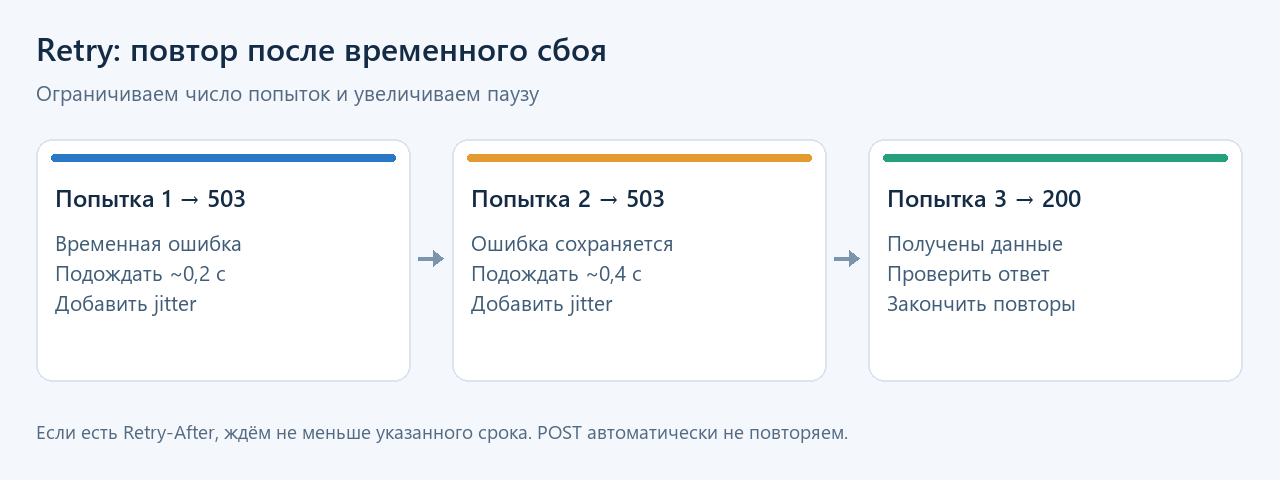

*Endpoint дважды отвечает 503, затем 200.*

In [20]:
import random
from datetime import datetime, timezone
from email.utils import parsedate_to_datetime


def retry_after_seconds(value):
    if value is None:
        return 0.0
    value = value.strip()
    if value.isdigit():
        return float(value)
    try:
        instant = parsedate_to_datetime(value)
        if instant.tzinfo is None:
            instant = instant.replace(tzinfo=timezone.utc)
        return max(0.0, (instant - datetime.now(timezone.utc)).total_seconds())
    except (ValueError, TypeError, OverflowError):
        return 0.0


def get_with_retry(http, url, max_attempts=4, base_delay=0.2, max_total_wait=5):
    if max_attempts < 1:
        raise ValueError("Нужна хотя бы одна попытка")
    total_wait = 0.0
    for attempt in range(1, max_attempts + 1):
        response = None
        network_error = None
        try:
            response = http.get(url, timeout=HTTP_TIMEOUT)
        except requests.exceptions.SSLError:
            raise
        except (requests.ConnectionError, requests.Timeout) as error:
            network_error = error
            print(f"Попытка {attempt}: {type(error).__name__}")
        else:
            print(f"Попытка {attempt}: HTTP {response.status_code}")
            if response.status_code not in {429, 502, 503, 504}:
                response.raise_for_status()
                return response

        if attempt == max_attempts:
            if network_error is not None:
                raise network_error
            response.raise_for_status()

        backoff = min(2.0, base_delay * 2 ** (attempt - 1))
        server_wait = retry_after_seconds(response.headers.get("Retry-After")) if response is not None else 0
        delay = max(backoff + random.uniform(0, backoff * 0.2), server_wait)
        if response is not None:
            response.close()
        if total_wait + delay > max_total_wait:
            raise RuntimeError("Ожидание превысит бюджет; новые попытки прекращены")
        print(f"Ждём {delay:.2f} с")
        time.sleep(delay)
        total_wait += delay


with demo_service() as (base_url, http):
    response = get_with_retry(http, f"{base_url}/unstable")
    print("Результат:", response.json())
    assert response.json()["attempt"] == 3

Попытка 1: HTTP 503
Ждём 0.22 с


Попытка 2: HTTP 503
Ждём 0.47 с


Попытка 3: HTTP 200
Результат: {'message': 'Сервис восстановился', 'attempt': 3}


### 5.3. Rate limiting: сервер ограничивает число запросов

Лимит демонстрации — два запроса за секундное окно.
Третий быстрый запрос получает **429 Too Many Requests** и `Retry-After: 1`.
Клиент ждёт и продолжает.

Лимит может считаться по ключу, пользователю, IP, endpoint или нескольким признакам.
Наш сервер считает общий лимит одного демонстрационного endpoint.
`X-RateLimit-*` здесь учебные: названия и смысл заголовков зависят от конкретного сервиса.

**Retry** реагирует на отказ. **Ограничение темпа клиента** заранее замедляет обращения.
Параллелизм не отменяет квоту; добавление потоков может быстрее её исчерпать.
Другие алгоритмы сервера: скользящее окно и token bucket — корзина с постепенно пополняемыми разрешениями.

Стандарт 429: [RFC 6585, раздел 4](https://www.rfc-editor.org/rfc/rfc6585.html#section-4).

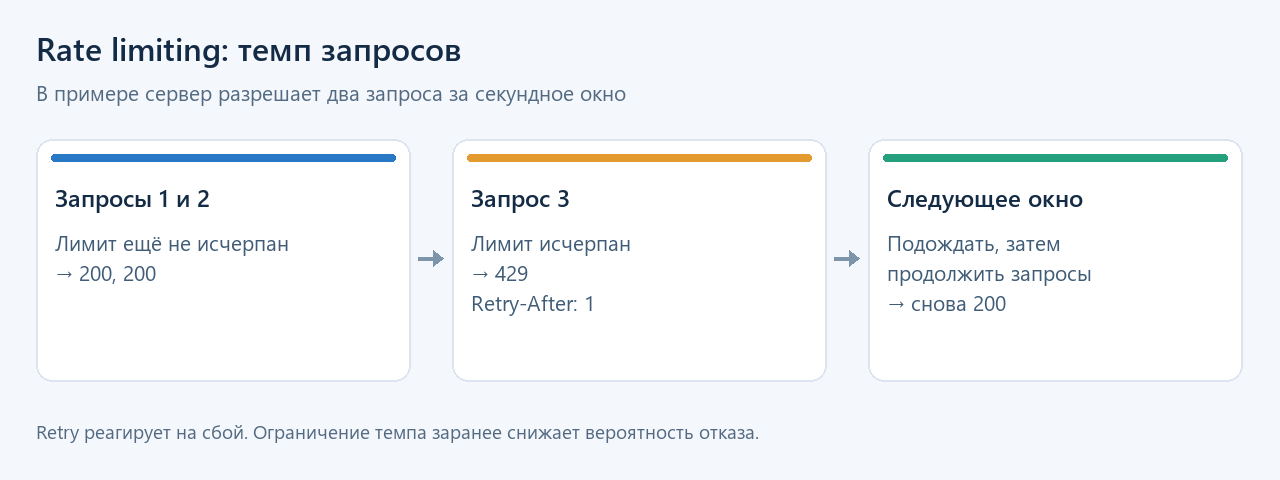

*Проверяем лимит на свежем локальном сервере.*

In [21]:
with demo_service() as (base_url, http):
    url = f"{base_url}/limited"
    statuses = []
    for number in range(1, 4):
        response = http.get(url, timeout=HTTP_TIMEOUT)
        statuses.append(response.status_code)
        print(f"Быстрый запрос {number}: {response.status_code}; "
              f"осталось {response.headers.get('X-RateLimit-Remaining')}; "
              f"Retry-After={response.headers.get('Retry-After')}")
    assert statuses == [200, 200, 429]
    recovered = get_with_retry(http, url)
    print("После ожидания:", recovered.status_code)
    assert recovered.status_code == 200

Быстрый запрос 1: 200; осталось 1; Retry-After=None
Быстрый запрос 2: 200; осталось 0; Retry-After=None
Быстрый запрос 3: 429; осталось 0; Retry-After=1
Попытка 1: HTTP 429
Ждём 1.00 с


Попытка 2: HTTP 200
После ожидания: 200


### Дополнительно E. Снижаем темп заранее

На свежем сервере делаем четыре обращения с паузой 0,55 секунды между ними.
Для нашего лимита 2/сек это позволяет обойтись без 429.
Реальный темп выбирают по документации сервиса и его ответам.

In [22]:
with demo_service() as (base_url, http):
    statuses = []
    for number in range(1, 5):
        if number > 1:
            time.sleep(0.55)
        response = http.get(f"{base_url}/limited", timeout=HTTP_TIMEOUT)
        statuses.append(response.status_code)
        print("Запрос с паузой", number, "→", response.status_code)
    assert statuses == [200, 200, 200, 200]

Запрос с паузой 1 → 200


Запрос с паузой 2 → 200


Запрос с паузой 3 → 200


Запрос с паузой 4 → 200


# 6. Веб-скрейпинг, robots.txt и JavaScript-страницы

**9 минут:** HTML и селекторы (3), robots.txt (2), браузерный рендеринг (4).

### 6.1. Когда данные находятся в HTML

В API получаем структурированные данные по контракту.
При скрейпинге разбираем HTML и выбираем элементы страницы.
У каждой книги в примере есть `article.book`, ссылка `.title`, автор `.author` и цена `.price`.

Сначала проверим правила обхода, затем извлечём карточки через BeautifulSoup.
Регулярные выражения не заменяют HTML-парсер.
Вёрстка может измениться: если ожидаемые элементы пропали, проверяем парсер,
а не считаем, что каталог стал пустым.

Справка по селекторам: [Beautiful Soup](https://www.crummy.com/software/BeautifulSoup/bs4/doc/).

### 6.2. robots.txt: правила для автоматического обхода

Файл находится в корне сервиса: `/robots.txt`.
`User-agent` задаёт группу роботов, `Disallow` запрещает пути, `Allow` разрешает их.
В учебном файле закрыт `/private/`, а каталог открыт.
`Crawl-delay` — распространённое расширение; его поддерживают не все роботы,
и оно не входит в основной RFC 9309.

robots.txt не является системой контроля доступа или разрешением на любые действия.
Клиент сам учитывает правила; `requests` и Playwright автоматически их не проверяют.
Если robots.txt недоступен из-за 5xx или сетевой ошибки, обход следует остановить;
отсутствие файла с 404 — отдельная ситуация, а не то же самое, что ошибка сети.

Скачиваем файл с явным таймаутом и передаём текст в `RobotFileParser`.
Для сложных правил нужен парсер, проверенный на актуальный стандарт;
здесь используем простые непересекающиеся правила.

Источники: [RFC 9309](https://www.rfc-editor.org/rfc/rfc9309.html),
[Python — robotparser](https://docs.python.org/3/library/urllib.robotparser.html).

In [23]:
from urllib.robotparser import RobotFileParser

BOT_NAME = "SeminarBot"


def get_robots(http, base_url):
    response = http.get(f"{base_url}/robots.txt", timeout=HTTP_TIMEOUT)
    response.raise_for_status()  # в учебном сценарии требуем успешно полученные правила
    rules = RobotFileParser()
    rules.set_url(f"{base_url}/robots.txt")
    rules.parse(response.text.splitlines())
    return rules


with demo_service() as (base_url, http):
    http.headers["User-Agent"] = BOT_NAME + "/1.0"
    rules = get_robots(http, base_url)
    for route in ["/catalog", "/catalog-js", "/public/books-data", "/private/report"]:
        print(route, "→", "можно обходить" if rules.can_fetch(BOT_NAME, base_url + route) else "пропускаем")
    print("Crawl-delay:", rules.crawl_delay(BOT_NAME), "секунда")
    assert rules.can_fetch(BOT_NAME, base_url + "/catalog")
    assert not rules.can_fetch(BOT_NAME, base_url + "/private/report")
    # Закрытую страницу не запрашиваем.

/catalog → можно обходить
/catalog-js → можно обходить
/public/books-data → можно обходить
/private/report → пропускаем
Crawl-delay: 1 секунда


### 6.3. Из HTML — в список записей

`.select("article.book")` находит карточки CSS-селектором;
`.select_one(".title")` — элемент внутри карточки;
`.get_text(strip=True)` — текст, а `element["href"]` — атрибут.
Относительную ссылку превращаем в абсолютную через `urljoin`.
Цену берём из машинного атрибута `data-price` и преобразуем в `Decimal`.

**Вопрос:** почему число найденных карточек полезно проверять?

In [24]:
from bs4 import BeautifulSoup
from decimal import Decimal


def parse_catalog(html_text, page_url):
    soup = BeautifulSoup(html_text, "html.parser")
    records = []
    for card in soup.select("article.book"):
        title = card.select_one(".title")
        author = card.select_one(".author")
        price = card.select_one(".price")
        if title is None or author is None or price is None:
            raise ValueError("Карточка не соответствует ожидаемой разметке")
        records.append({"id": int(card["data-id"]), "title": title.get_text(strip=True),
                        "author": author.get_text(strip=True), "price": Decimal(price["data-price"]),
                        "url": urljoin(page_url, title["href"])})
    return records


with demo_service() as (base_url, http):
    http.headers["User-Agent"] = BOT_NAME + "/1.0"
    rules = get_robots(http, base_url)
    url = f"{base_url}/catalog"
    if not rules.can_fetch(BOT_NAME, url):
        raise PermissionError("Обход страницы запрещён robots.txt")
    time.sleep(rules.crawl_delay(BOT_NAME) or 0)
    response = http.get(url, timeout=HTTP_TIMEOUT)
    response.raise_for_status()
    assert response.headers["Content-Type"].startswith("text/html")
    scraped = parse_catalog(response.text, url)
    for book in scraped[:3]:
        print(book["title"], "|", book["price"], "₽ |", book["url"])
    print("Всего карточек:", len(scraped))
    assert len(scraped) == 8

Python для начинающих | 599.00 ₽ | http://127.0.0.1:50182/books/1
Компьютерные сети | 699.00 ₽ | http://127.0.0.1:50182/books/2
HTTP на практике | 799.00 ₽ | http://127.0.0.1:50182/books/3
Всего карточек: 8


### 6.4. Почему requests не видит данные JS-страницы

У `/catalog-js` исходный HTML содержит пустой список и JavaScript.
Браузер выполняет `fetch('/public/books-data')`, получает JSON и создаёт карточки в DOM.
`requests` загружает ответ, но не исполняет JavaScript.

Есть два пути:

1. Если доступен подходящий endpoint данных, обращаться к нему напрямую.
2. Если нужны результат рендеринга или действия на странице, использовать браузер.

На настоящем сайте запросы страницы удобно исследовать в DevTools → Network → Fetch/XHR.
Обнаруженный endpoint может требовать аутентификацию и иметь ограничения.

Иллюстрации: [MDN — Client-server overview](https://developer.mozilla.org/en-US/docs/Learn_web_development/Extensions/Server-side/First_steps/Client-Server_overview).

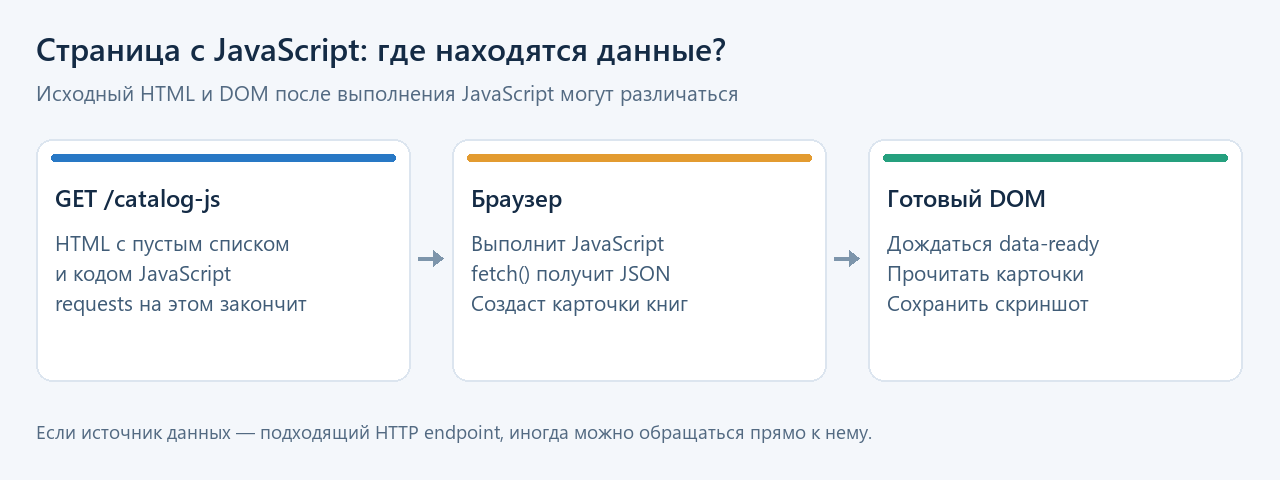

*Сравниваем два способа на одной локальной странице.*

In [25]:
with demo_service() as (base_url, http):
    http.headers["User-Agent"] = BOT_NAME + "/1.0"
    rules = get_robots(http, base_url)
    url = f"{base_url}/catalog-js"
    assert rules.can_fetch(BOT_NAME, url)
    assert rules.can_fetch(BOT_NAME, base_url + "/public/books-data")
    time.sleep(rules.crawl_delay(BOT_NAME) or 0)
    response = http.get(url, timeout=HTTP_TIMEOUT)
    response.raise_for_status()
    source_records = parse_catalog(response.text, url)
    print("Карточек в исходном HTML:", len(source_records))
    print("В HTML есть код fetch():", "fetch(" in response.text)
    time.sleep(rules.crawl_delay(BOT_NAME) or 0)
    data = get_json(http, f"{base_url}/public/books-data")
    print("Записей в endpoint данных:", len(data["items"]))
    assert source_records == [] and len(data["items"]) == 8

Карточек в исходном HTML: 0
В HTML есть код fetch(): True


Записей в endpoint данных: 8


### 6.5. Настоящий браузер: ждём готовый DOM

Playwright открывает страницу в отдельном браузерном процессе.
На Windows используем установленный Edge, при его отсутствии — Chromium Playwright.
На другой машине Chromium нужно заранее установить: `python -m playwright install chromium`.

Для совместимости с Jupyter на Windows запускаем браузер в отдельном потоке.
Подготовительную ячейку можно свернуть; результат получаем через `await asyncio.to_thread(...)`.
Ждём признак завершения `#books[data-ready='true']`, а не случайную паузу «на всякий случай».
После рендеринга разбираем HTML тем же парсером и сохраняем настоящий скриншот.
На этой учебной странице fetch запускается с паузой больше секунды, с учётом Crawl-delay.
У произвольного сайта браузер делает много подзапросов: их темп нужно контролировать отдельно.

Справка: [Playwright Python](https://playwright.dev/python/docs/library),
[браузеры и Edge](https://playwright.dev/python/docs/browsers).

In [26]:
import asyncio
import os
from pathlib import Path
from playwright.async_api import async_playwright
from IPython.display import Image, display

OUTPUT_DIR = Path("seminar_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)


async def render_catalog(url):
    async with async_playwright() as playwright:
        edge_paths = [Path("C:/Program Files (x86)/Microsoft/Edge/Application/msedge.exe"),
                      Path("C:/Program Files/Microsoft/Edge/Application/msedge.exe")]
        options = {"channel": "msedge"} if os.name == "nt" and any(p.is_file() for p in edge_paths) else {}
        browser = await playwright.chromium.launch(headless=True, **options)
        try:
            page = await browser.new_page(viewport={"width": 1200, "height": 780},
                                          user_agent=BOT_NAME + "/1.0")
            navigation = await page.goto(url, wait_until="domcontentloaded", timeout=10000)
            assert navigation is not None and navigation.status == 200
            await page.locator("#books[data-ready='true']").wait_for(timeout=10000)
            records = parse_catalog(await page.content(), url)
            screenshot = OUTPUT_DIR / "js_catalog.png"
            await page.screenshot(path=str(screenshot), full_page=True)
            return records, screenshot
        finally:
            await browser.close()


def render_in_worker(url):
    # Отдельный loop с поддержкой subprocess: основной loop Jupyter на Windows
    # может быть SelectorEventLoop, несовместимым с запуском драйвера браузера.
    loop = asyncio.ProactorEventLoop() if os.name == "nt" else asyncio.new_event_loop()
    try:
        return loop.run_until_complete(render_catalog(url))
    finally:
        loop.run_until_complete(loop.shutdown_asyncgens())
        loop.run_until_complete(loop.shutdown_default_executor())
        loop.close()


print("Подготовлен браузерный рендеринг в отдельном потоке.")

Подготовлен браузерный рендеринг в отдельном потоке.


Карточек после JavaScript: 8
Первая книга: Python для начинающих


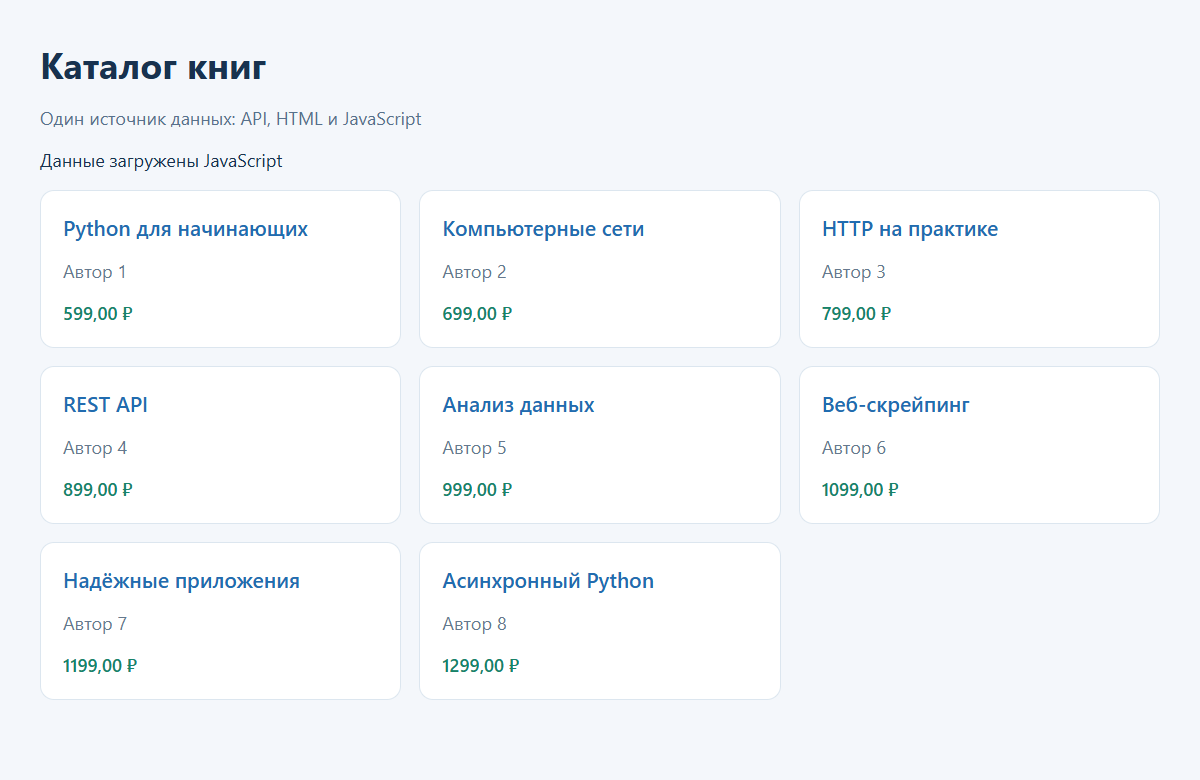

In [27]:
with demo_service() as (base_url, http):
    http.headers["User-Agent"] = BOT_NAME + "/1.0"
    rules = get_robots(http, base_url)
    url = f"{base_url}/catalog-js"
    for allowed_url in [url, f"{base_url}/public/books-data"]:
        if not rules.can_fetch(BOT_NAME, allowed_url):
            raise PermissionError("Обход запрещён robots.txt")
    await asyncio.sleep(rules.crawl_delay(BOT_NAME) or 0)
    rendered_records, screenshot = await asyncio.to_thread(render_in_worker, url)

print("Карточек после JavaScript:", len(rendered_records))
print("Первая книга:", rendered_records[0]["title"])
assert len(rendered_records) == 8
display(Image(filename=str(screenshot), width=1000))

# 7. Итоги: выбираем способ получения данных

**Последние 3 минуты — итоговый пример и вопросы.**

| Ситуация | Подход |
|---|---|
| Есть подходящий API | Контракт → аутентификация → JSON |
| API выдаёт данные частями | Следовать next до конца |
| Временные ошибки или 429 | Ограниченные повторы, паузы и Retry-After |
| Данные уже в HTML | robots.txt → HTTP → HTML-парсер |
| Данные появляются после JavaScript | Проверить endpoint данных или запустить браузер |

### Один клиент: ключ + страницы + временные сбои + лимит

Endpoint с `resilient=1` сначала имитирует сбои 503 и ограничивает частоту.
Повторяем безопасный GET, соблюдаем ожидание и собираем все страницы.

In [28]:
def resilient_json(http, url):
    response = get_with_retry(http, url)
    if not response.headers.get("Content-Type", "").startswith("application/json"):
        raise ValueError("Ожидался JSON")
    return response.json()


with demo_service() as (base_url, http):
    http.headers.update({"X-API-Key": "demo-reader-key", "Accept": "application/json"})
    books = collect_books(
        http, f"{base_url}/api/v1/books?page=1&per_page=3&resilient=1",
        fetch=resilient_json,
    )
    print("ИТОГ:", len(books), "книг без пропусков; id:", [b["id"] for b in books])
    assert [b["id"] for b in books] == list(range(1, 9))

Попытка 1: HTTP 503
Ждём 0.23 с


Попытка 2: HTTP 503
Ждём 0.46 с


Попытка 3: HTTP 429
Ждём 1.00 с


Попытка 4: HTTP 200
Страница 1: 3 записей
Попытка 1: HTTP 200
Страница 2: 3 записей
Попытка 1: HTTP 429
Ждём 1.00 с


Попытка 2: HTTP 200
Страница 3: 2 записей
ИТОГ: 8 книг без пропусков; id: [1, 2, 3, 4, 5, 6, 7, 8]


### Финальные вопросы

1. Почему JSON поверх HTTP ещё не означает полное соответствие REST?
2. Как различить неверный ключ и недостаточные права?
3. Как понять, что все страницы получены?
4. Почему повтор POST после таймаута может создать дубликат?
5. Чем retry отличается от ограничения темпа клиента?
6. Почему BeautifulSoup не находит карточки в исходном HTML JS-страницы?

<details>
<summary>Ответы для ведущего</summary>

1. REST задаёт архитектурные ограничения; формат JSON — выбор представления.
2. В примере 401 — ключ отсутствует или неверен, 403 — прав недостаточно.
3. По контракту пагинации: в нашем API next равен null.
4. Сервер мог выполнить создание, а клиент не получил ответ; повтор создаст ещё один ресурс.
5. Retry повторяет после временного отказа, ограничение темпа предотвращает частые обращения.
6. Карточки создаёт JavaScript; HTML-парсер этот код не исполняет.

</details>

**Практика после семинара:** измените `per_page` с 3 на 2, попробуйте admin с ключом читателя,
измените селектор `.title` и объясните полученную ошибку.

## Статьи и иллюстрации для доклада

| Источник | Что можно показать | Куда вставить |
|---|---|---|
| [Cloudflare: How does the Internet work?](https://www.cloudflare.com/learning/network-layer/how-does-the-internet-work/) | Иллюстрации сети и загрузки веб-страницы | Общая картина |
| [Cloudflare: What is TCP/IP?](https://www.cloudflare.com/learning/ddos/glossary/tcp-ip/) | Схема TCP handshake | Установление соединения |
| [Cloudflare: What is a computer port?](https://www.cloudflare.com/learning/network-layer/what-is-a-computer-port/) | Объяснение портов и схема уровней OSI | IP и порт |
| [MDN: How does the Internet work?](https://developer.mozilla.org/en-US/docs/Learn_web_development/Howto/Web_mechanics/How_does_the_Internet_work) | Схемы соединения компьютеров, коммутаторов и сетей | Общая картина |
| [Beej: Client-Server Background](https://beej.us/guide/bgnet/html/split/client-server-background.html) | Схема взаимодействия клиента и сервера в начале статьи | Перед echo-примером |
| [Wikimedia Commons: Tcp-handshake.svg](https://commons.wikimedia.org/wiki/File:Tcp-handshake.svg) | Масштабируемая SVG-схема handshake | TCP |

Под картинкой удобно оставить ссылку на статью.
Для Wikimedia авторство и условия CC BY-SA 3.0 указаны на странице файла;
для остальных источников условия использования иллюстраций нужно смотреть отдельно.
Картинки с сайтов пока не встроены: ноутбук полностью читается и запускается офлайн.

**Справка по коду:**
[модуль socket](https://docs.python.org/3/library/socket.html) ·
[Socket Programming HOWTO](https://docs.python.org/3/howto/sockets.html) ·
[Beej: Introducing the Sockets API](https://beej.us/guide/bgnet0/html/split/introducing-the-sockets-api.html).
### HTTP: справка и картинки

| Источник | Что взять для доклада |
|---|---|
| [MDN — Overview of HTTP](https://developer.mozilla.org/en-US/docs/Web/HTTP/Guides/Overview) | Схемы клиент–сервер, запроса и ответа |
| [MDN — HTTP messages](https://developer.mozilla.org/en-US/docs/Web/HTTP/Guides/Messages) | Иллюстрации частей HTTP-сообщения |
| [MDN — Methods](https://developer.mozilla.org/en-US/docs/Web/HTTP/Reference/Methods) | Семантика методов, безопасность и идемпотентность |
| [MDN — Status codes](https://developer.mozilla.org/en-US/docs/Web/HTTP/Reference/Status) | Значения кодов состояния |
| [Requests — Quickstart](https://requests.readthedocs.io/en/latest/user/quickstart/) | GET, параметры, заголовки, JSON и ошибки |
| [Python — http.server](https://docs.python.org/3/library/http.server.html) | Устройство локального учебного сервера |


### REST, устойчивый клиент и скрейпинг: сайты и картинки

| Источник | Для чего полезен |
|---|---|
| [Fielding — REST](https://ics.uci.edu/~fielding/pubs/dissertation/rest_arch_style.htm) | Определение REST и схемы архитектурных ограничений |
| [RFC 6750](https://www.rfc-editor.org/rfc/rfc6750.html) | Передача Bearer-токена |
| [GitHub — pagination](https://docs.github.com/en/rest/using-the-rest-api/using-pagination-in-the-rest-api) | Реальный контракт выдачи и Link |
| [Microsoft — retry pattern](https://learn.microsoft.com/en-us/azure/architecture/patterns/retry) | Схема повторов запросов |
| [MDN — Retry-After](https://developer.mozilla.org/en-US/docs/Web/HTTP/Reference/Headers/Retry-After) | Секунды и HTTP-дата |
| [Cloudflare — rate limiting](https://www.cloudflare.com/learning/bots/what-is-rate-limiting/) | Иллюстрации ограничения частоты |
| [RFC 9309 — robots.txt](https://www.rfc-editor.org/rfc/rfc9309.html) | Формат и смысл правил обхода |
| [Python — robotparser](https://docs.python.org/3/library/urllib.robotparser.html) | Программная проверка robots.txt |
| [Beautiful Soup](https://www.crummy.com/software/BeautifulSoup/bs4/doc/) | HTML-парсинг и CSS-селекторы |
| [MDN — Client-server overview](https://developer.mozilla.org/en-US/docs/Learn_web_development/Extensions/Server-side/First_steps/Client-Server_overview) | Иллюстрации статического и динамического обмена |
| [Playwright Python](https://playwright.dev/python/docs/library) | Запуск браузера и примеры кода |

Семь схем подготовлены специально для семинара и встроены в файл как attachments.
Их PNG-копии находятся в `seminar_figures/`; можете использовать их в своих слайдах.
Скриншот `seminar_outputs/js_catalog.png` получен при выполнении JavaScript в браузере.
Для заимствованных иллюстраций сохраняйте источник и проверяйте условия использования.
